In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-notebook')
import numpy as np
import seaborn as sns
import warnings
from data_profiling import ProfileReport
import scipy.stats as stats
from scipy.stats import shapiro
from scipy import stats
SEED = 42

In [2]:
%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
data = pd.read_csv('./data/train.csv')

In [4]:
data

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,6,5,1999,2000,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0,Unf,0,953,953,GasA,Ex,Y,SBrkr,953,694,0,1647,0,0,2,1,3,1,TA,7,Typ,1,TA,Attchd,1999.0,RFn,2,460,TA,TA,Y,0,40,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,Norm,1Fam,1Story,6,6,1978,1988,Gable,CompShg,Plywood,Plywood,Stone,119.0,TA,TA,CBlock,Gd,TA,No,ALQ,790,Rec,163,589,1542,GasA,TA,Y,SBrkr,2073,0,0,2073,1,0,2,0,3,1,TA,7,Min1,2,TA,Attchd,1978.0,Unf,2,500,TA,TA,Y,349,0,0,0,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,

In [5]:
data.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
len(data.columns)

81

In [7]:
data.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [8]:
# profile = ProfileReport(data, title="Profiling Report")
# profile.to_file("report.html")

# Анализ признаков после просмотра отчета 

    Мысли по каждому из признаку
- MSSubClass - 36% домов это одноэтажные дома 1946 года постройки или новее, любого стиля, 20% это двухэтажные дома 1946 года постройки или новее, медиана это полуторо этажный дом, переменная дискретная, цифра не отражает значимость категории, можно попробовать превратить в ранговую переменную в соотвествии с средней ценной в каждой категории 
- MSZoning - Большинство домов находятся в жилой зоне низкой плотности 78% остальные случаи появляются редко, первая мысль - Frequency Encoding
----------------------
- LotFrontage - 259 пропусков, есть потенциальные выбросы, распределение около-нормальное
- LotArea - площадь в кв.футах, так же есть выбросы, пропусков нет,много данных очень сильно сгрупированы вокруг среднего, но стандартное отклоненние и коэффициент вариации оч большие, что подтверждает что есть гигантские выборсы
----------------------
- Street - очень большой соблазн выкинуть так как 99.6% это твёрдое покрытие, возможно эти 6 гравийных покрытий это подъезды к каким то дорогущим замкам, и может зарешать, надо их изучить
- Alley - 93% процента выбросов, можно попробовать востановить, предварительная логика, что если улица с твердым покрытием, то и подход с переулка с твердым, но стоит погуглить
----------------------
- LotShape - общая форма участка преимущественно правильная (63%), более неправильные формы составляют 3% поэтому возможно стоит их объеденить, с незначительно неправильной формой, хотя возможно они так же относятся к каким то супер догорущим замкам, что стоит проверить
- LandContour - с рельефом участка сложнее, тоже очень мало остальных рельфов помимо ровного, тоже стоит изучить, пока тоже объеденить разные неровные рельефы в один
----------------------
- Utilities - убрать, так как один случай дома только с электричеством
- LotConfig - конфигурация участка, возможно стоит объеденить две последние категории, а так нормально
- LandSlope - Уклон участка, объеденить две категории в одну привести к бинарному признаку
- Neighborhood - Район расположения в пределах города Эймс, в дл обязательно сделать слой эмбедингов для таких признаков тут не знаю, пока идей нет
- Condition1 и Condition2, либо объеденить либо второе убрать
- BldgType - тип жилого здания, возможно тут нет замков по этой проверить выборсы
- HouseStyle - нормальный признак, пропусков нет
-----------------------
- OverallQual - ранговый признак удобно
- OverallCond - ранговый признак удобно
----------------------
- YearBuilt - надо бы посмотретть что сделать
- YearRemodAdd - может совпадать с годом постройки, возможно удалить 
----------------------
- RoofStyle -имбалансная может быть объеденить с RoofMatl
- RoofMatl - мб объеденить с RoofStyle
---------------------
- Exterior1st - мб объеденить с Exterior2nd
- Exterior2nd - мб объеденить с Exterior1st
--------------------
- MasVnrType - пропуски приравнять к осутсвию облицовки, проверить на MasVnrArea
- MasVnrArea - много нулей так как не у всех есть облицовка
--------------------
- ExterQual - ранговая переменная, перевести в цифры от 1 до 5
- ExterCond - ранговая переменная, перевести в цифры от 1 до 5
--------------------
- Foundation - пока без вопросов
- BsmtQual - ранговая, пропуски - значит нет подвала
- BsmtExposure - ранговая, пропуски - нет подвала
- BsmtFinType1 - ранговая, пропуски - нет подвала
- BsmtFinSF1 - пока ничего, пропуски - не отделывали подвал
- BsmtFinType2 - раговая
- BsmtFinSF2 - пока скип
- BsmtUnfSF - 
- TotalBsmtSF -  Мб из этого всего безобразия можно сделать пару фич по типу крутой отделанный подвал первого типа, и крутой отделанный подвал второго типа, в общем, подумать, все площади проверить на выбросы
---------------------
- Heating - тоже очень имбалансная, надо подумать как лучше закодировать
- HeatingQC - ранговая
- CentralAir - бинарная, без вопросов
-----------------------
- Electrical - сделать наверное три категории
-----------------------
- 1stFlrSF - проверить на выборсы
- 2ndFlrSF - проверить на выборсы, пропуски - нет второго этажа
-----------------------
- LowQualFinSF - какая то оч стремная фича, мб использовать для фича инжиниринга а так убрать
- GrLivArea - проверить на выбросы
-----------------------
- BsmtFullBath - сделать бинарной, есть нет
- BsmtHalfBath - так же сделать бинарной, есть нет
- FullBath - ну такая
- HalfBath - сделать есть нет
------------------------
- Bedroom - норм без вопросов
- KitchenAbvGr - можно сделать 1/2/3, 0 как то странно
- KitchenQual - ранговая
- TotRmsAbvGrd - првоерить на выборосы на всякий, нормальная
- Functional - надо погуглить, оч разряженная
- Fireplaces - сделать есть/нет
- FireplaceQu - ранговая, пропуски - нет каминов
----------------------------
- GarageType - пропуски нет гаража
- GarageYrBlt - проверить кореляцию с годом строительства дома, убрать
- GarageFinish - ранговая, позволяет востановить наличие гаража
- GarageCars - тоже можно сказать ранговая
- GarageArea - проверить на выбросы
- GarageQual - ранговая
- GarageCond - ранговая
--------------------------
- PavedDrive - дискретная
- WoodDeckSF - 0, нет терасы
- OpenPorchSF - Возможно если тут не 0 а в связанных с террасой 0, то значит есть крыльцо, но нет веранды
- EnclosedPorch- 0 - нету закрытой террасы
- ScreenPorch - 0 нет террасы с москитными сетками
--------------------------
- PoolArea - 0 нет бассейна
- PoolQC - ранговая
--------------------------
- Fence - 0, нет ограждения
- MiscFeature - возможно сделать фичу one-hottom
- MiscVal - проверить выбросы
--------------------------
##### Посмотреть что сделать с временными фичами, и как их лучше разбивать, возможно стоит сделать признак время с продажи по самомму последнему значению в трейне
- MoSold - месяц продажи
- YrSold - год продажи
- SaleType - тип сделки по продаже
- SaleCondition - условия продажи
- SalePrice - целевая, проверить выбросы



Разделить на дискертные и непрерывные переменные

## Начнем с исследования целевой переменной

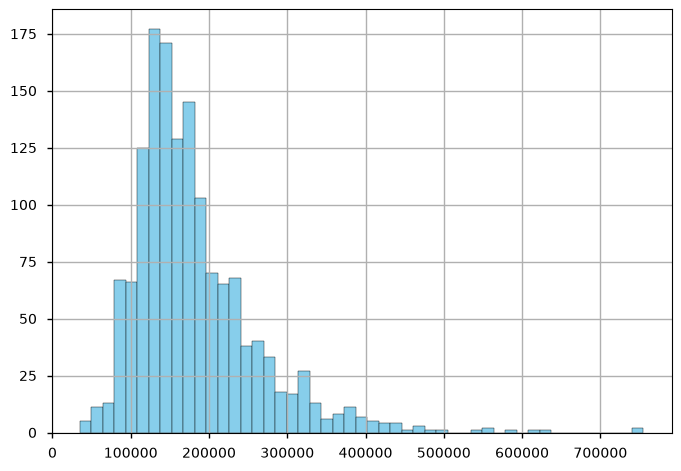

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

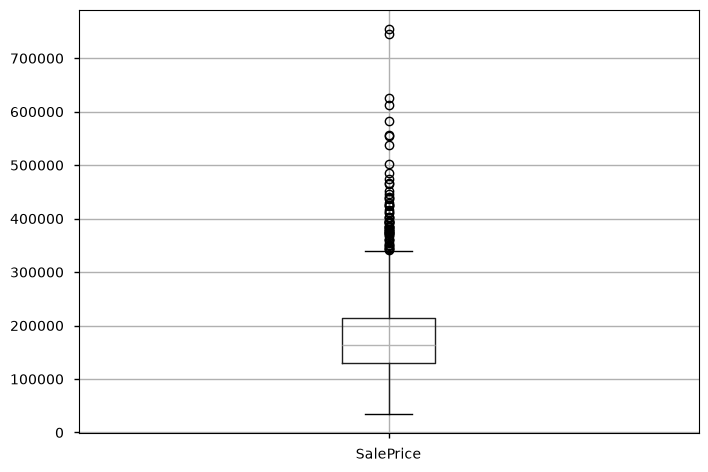

In [9]:
data['SalePrice'].hist(bins='fd', color='skyblue', edgecolor='black')
plt.show()
data.boxplot('SalePrice')
data['SalePrice'].describe()

Распределение смещено, и потенциально много значений подходящих под выбросы

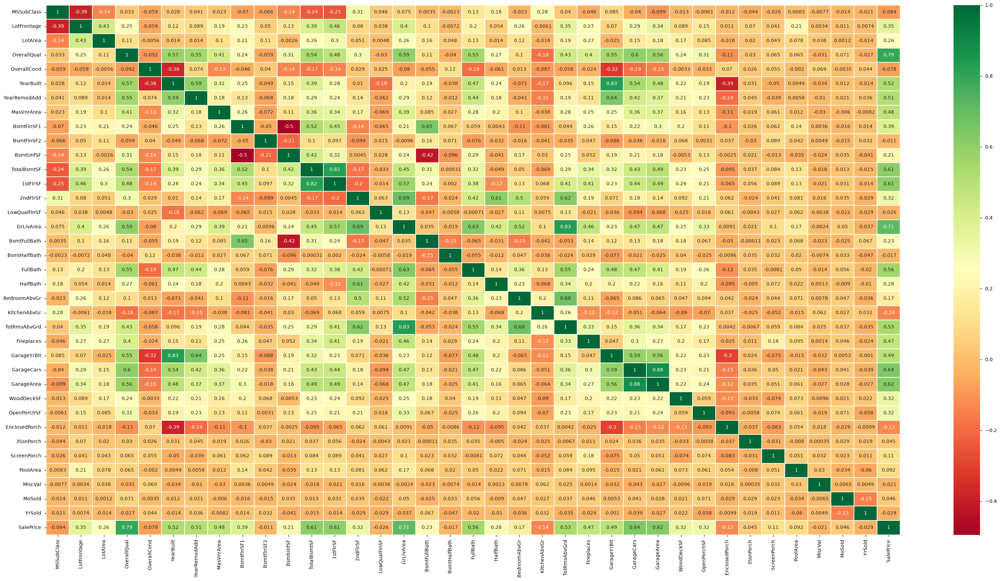

In [10]:
sns.heatmap(data.drop(columns=['Id']).corr(numeric_only = 'True'),annot=True,cmap='RdYlGn',linewidths=0.2,xticklabels=1,yticklabels=1) #df.corr()-->correlation matrix
fig=plt.gcf()
fig.set_size_inches(40,20)
plt.show()

In [11]:
data.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).head(6)

SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64

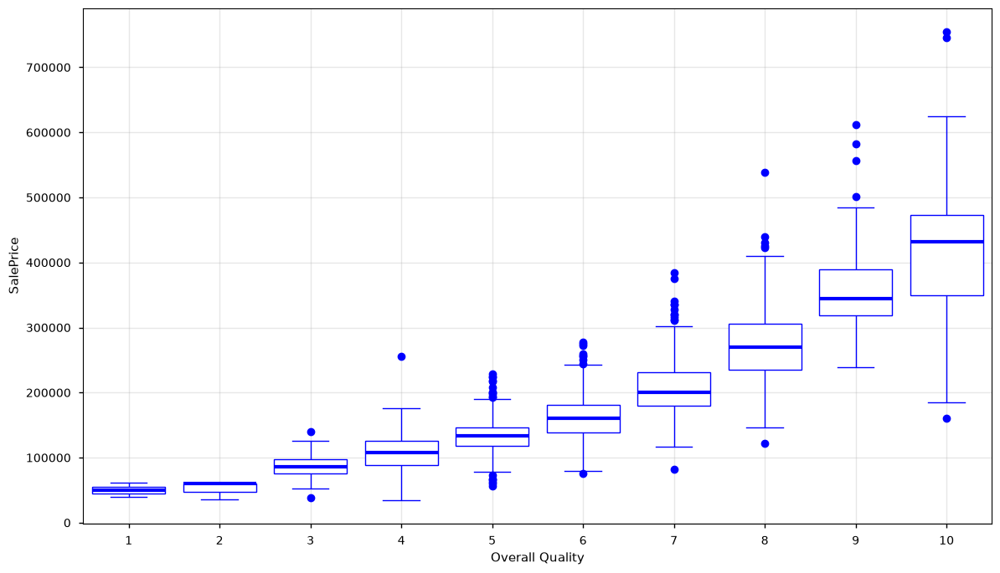

In [12]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='OverallQual',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('Overall Quality')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

По этому графику можно сделать вывод о положительной кореляции, признаку общее качество и цены, есть потенциально один выброс дорого дома с качеством 4

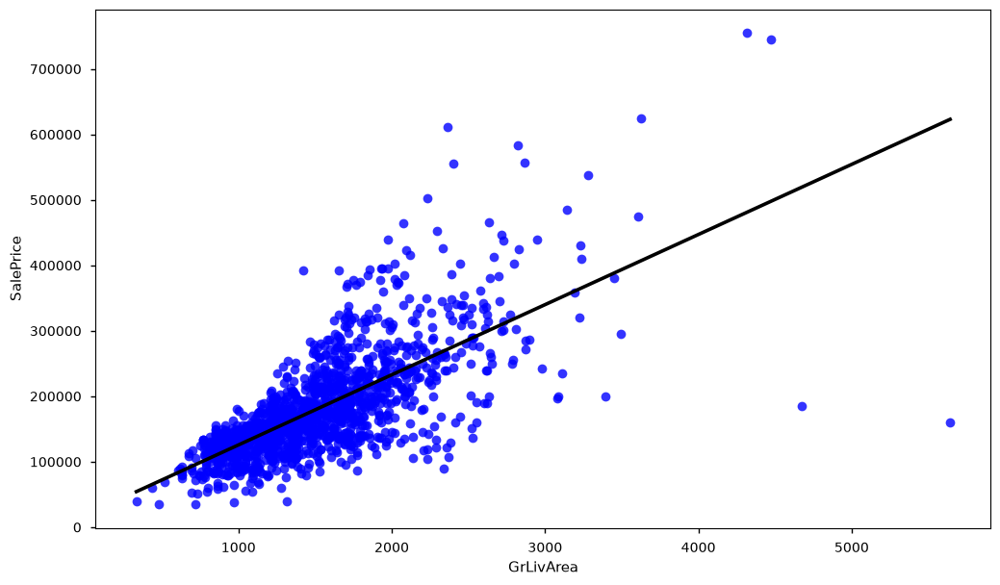

In [13]:
plt.figure(figsize=(12, 7))

sns.regplot(
    data=data,
    x='GrLivArea',
    y='SalePrice',
    ci=None,
    scatter_kws={'color': 'blue'},
    line_kws={'color': 'black'}
)

plt.show()

Вот эти 4 значения потенциально странные, наиболее удивляет огромная жилая площадь за сравнительно низкую цену, похоже на выброс

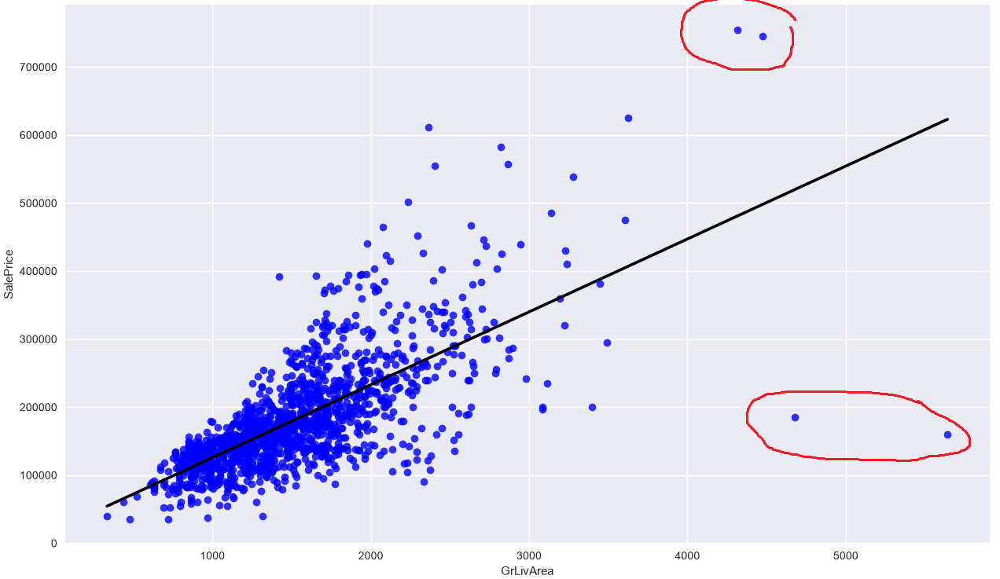

In [14]:
GrLivArea_outliers = data[data['GrLivArea']>4000].sort_values(by = 'GrLivArea')
GrLivArea_outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,Norm,Norm,1Fam,2Story,10,6,1994,1995,Gable,WdShngl,HdBoard,HdBoard,BrkFace,1170.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,1455,Unf,0,989,2444,GasA,Ex,Y,SBrkr,2444,1872,0,4316,0,1,3,1,4,1,Ex,10,Typ,2,Ex,Attchd,1994.0,Fin,3,832,TA,TA,Y,382,50,0,0,0,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,Norm,Norm,1Fam,2Story,10,5,1996,1996,Hip,CompShg,Wd Sdng,ImStucc,NaN,0.0,Gd,TA,PConc,Ex,TA,Av,GLQ,2096,Unf,0,300,2396,GasA,Ex,Y,SBrkr,2411,2065,0,4476,1,0,3,1,4,1,Ex,10,Typ,2,TA,Attchd,1996.0,Fin,3,813,TA,TA,Y,171,78,0,0,0,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000
523,524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,NaN,NaN,NaN,0,10,2007,New,Partial,184750
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


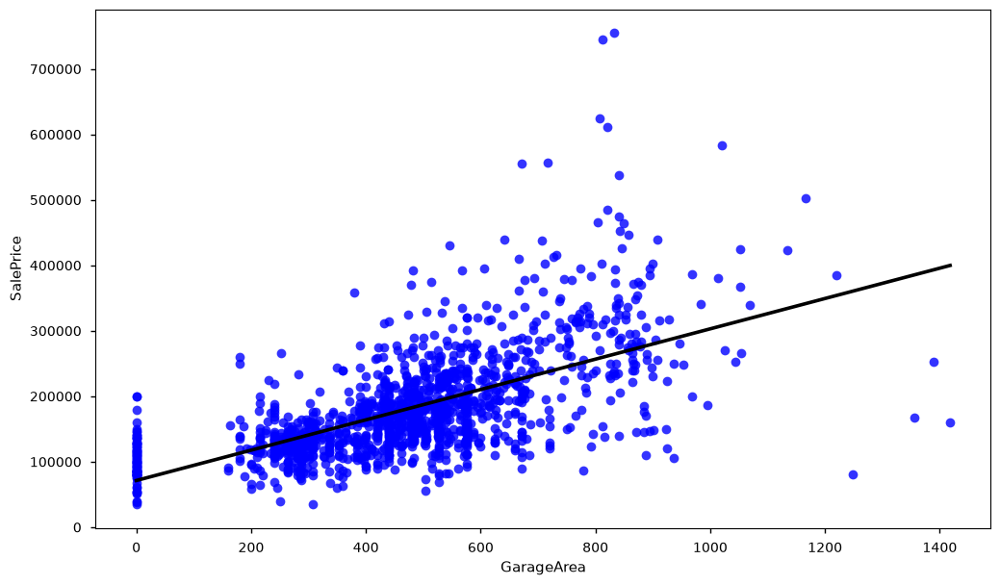

In [15]:
plt.figure(figsize=(12, 7))

sns.regplot(
    data=data,
    x='GarageArea',
    y='SalePrice',
    ci=None,
    scatter_kws={'color': 'blue'},
    line_kws={'color': 'black'}
)

plt.show() 

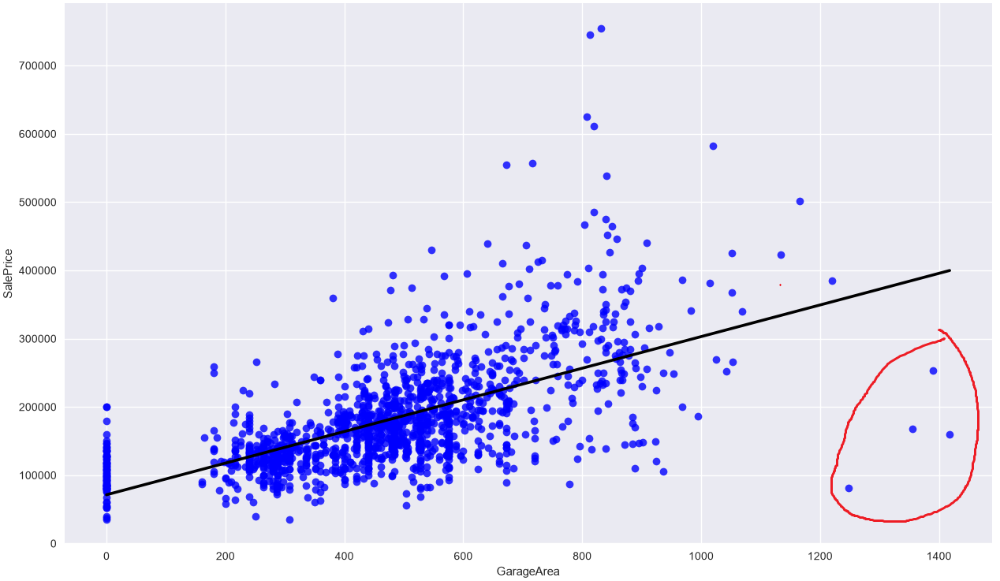

На данном графике вот эта кучка справа с огромной площадью гаража выглядит подозрительно

In [16]:
GarageArea_outliers = data[(data['GarageArea']>1100)&(data['SalePrice']<300000)].sort_values(by = 'GarageArea')
GarageArea_outliers

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1061,1062,30,C (all),120.0,18000,Grvl,NaN,Reg,Low,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,3,4,1935,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,Fa,TA,CBlock,TA,TA,No,Unf,0,Unf,0,894,894,GasA,TA,Y,SBrkr,894,0,0,894,0,0,1,0,2,1,TA,6,Typ,0,NaN,Detchd,1994.0,RFn,3,1248,TA,TA,Y,0,20,0,0,0,0,NaN,NaN,Shed,560,8,2008,ConLD,Normal,81000
1190,1191,190,RL,NaN,32463,Pave,NaN,Reg,Low,AllPub,Inside,Mod,Mitchel,Norm,Norm,2fmCon,1Story,4,4,1961,1975,Gable,CompShg,MetalSd,MetalSd,Stone,149.0,TA,Gd,CBlock,TA,TA,Av,BLQ,1159,Unf,0,90,1249,GasA,Ex,Y,SBrkr,1622,0,0,1622,1,0,1,0,3,1,TA,7,Typ,1,TA,2Types,1975.0,Fin,4,1356,TA,TA,Y,439,0,0,0,0,0,NaN,NaN,NaN,0,3,2007,WD,Normal,168000
581,582,20,RL,98.0,12704,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NridgHt,Norm,Norm,1Fam,1Story,8,5,2008,2009,Hip,CompShg,VinylSd,VinylSd,BrkFace,306.0,Ex,TA,PConc,Ex,TA,No,Unf,0,Unf,0,2042,2042,GasA,Ex,Y,SBrkr,2042,0,0,2042,0,0,2,1,3,1,Ex,8,Typ,1,Gd,Attchd,2009.0,RFn,3,1390,TA,TA,Y,0,90,0,0,0,0,NaN,NaN,NaN,0,8,2009,New,Partial,253293
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


Так же посмотрим кореляциб в кол-вом машин в гараже

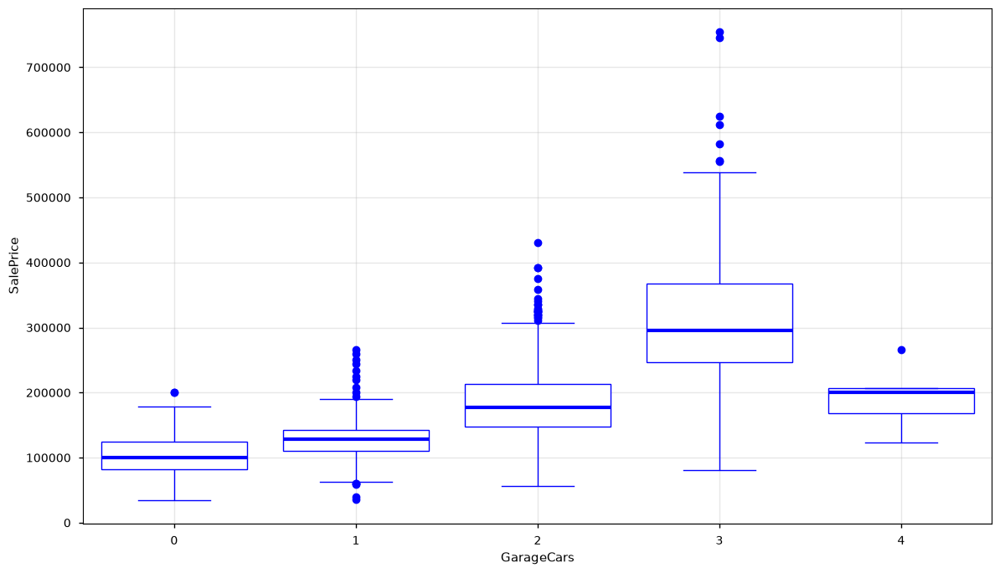

In [17]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='GarageCars',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('GarageCars')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

По количеству машин в гараже явных выбросов не наблюдается, но и прямой корелляции так же не наблюдается, тут более сложная нелинейная зависимость

Посмотрим сколько у нас экстримальных значений по цене

In [18]:
mean = data['SalePrice'].mean()
std = data['SalePrice'].std()
upper = mean + 3 * std
outliers = data[data['SalePrice'] > upper]
print(len(outliers))

22


### Пропуски в данных и кодирование переменных

In [19]:
nulls = data.isnull().sum()
nulls = nulls[nulls != 0]
nulls

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

## LotFrontage
Заполнить медианой по району

<Axes: xlabel='LotFrontage', ylabel='Neighborhood'>

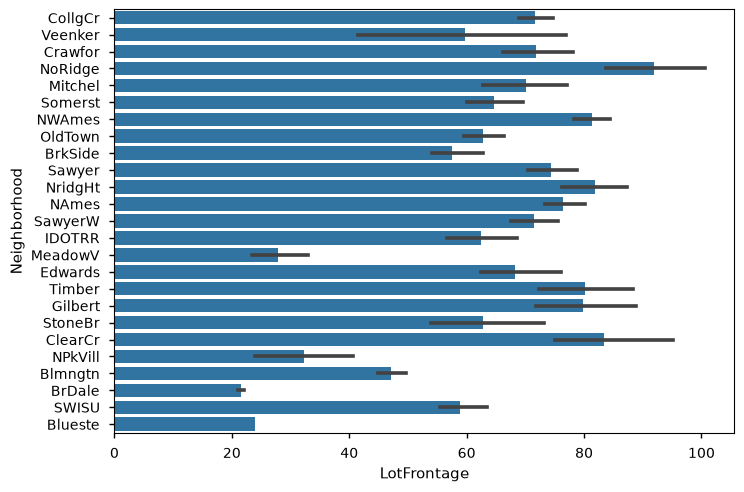

In [20]:
sns.barplot(x = 'LotFrontage',y = 'Neighborhood',data=data)

In [ ]:
median_frontage = data.groupby('Neighborhood')['LotFrontage'].transform('median')
data['LotFrontage'] = data['LotFrontage'].fillna(median_frontage)

## Alley
Можно заменить ван-хот колонками

In [22]:
data['Alley'].value_counts()

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

In [23]:
data['Alley'] = data['Alley'].fillna('NA')

## MasVnrType
Можно востановить по признаку MasVnrArea, заменить значения где пропуск и есть MasVnrArea, на BrkFace, попробовать оценить их стоимость
- MasVnrType: Тип облицовки каменной или кирпичной кладкой

       BrkCmn	Обычный кирпич
       BrkFace	Облицовочный кирпич
       CBlock	Шлакоблок
       None	Отсутствует
       Stone	Камень
	
- MasVnrArea: Площадь облицовки каменной или кирпичной кладкой в квадратных футах
 
Пропусков у MasVnrType, но при этом мало у MasVnrArea:
- MasVnrType       872
- MasVnrArea         8

Можно посмотреть на соотношение вида облицовки и стоимости и проранжировать их стоимость

In [24]:
data['MasVnrType'].value_counts()

MasVnrType
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [25]:
data['MasVnrArea'].value_counts()

MasVnrArea
0.0      861
108.0      8
72.0       8
180.0      8
16.0       7
        ... 
426.0      1
96.0       1
438.0      1
194.0      1
119.0      1
Name: count, Length: 327, dtype: int64

Посмотрим сначала пропуски в MasVnrArea, так как их меньше

In [26]:
len(data.loc[
    (data['MasVnrType'].notna()) &
    (data['MasVnrArea'].isna())
])

0

Так как пропусков в данных, где есть тип облицовки, но нет площади - нет, заполним их 0

In [27]:
data['MasVnrArea'] = data['MasVnrArea'].fillna(0.0)
data.loc[(data['MasVnrType'].isna()) & (data['MasVnrArea']==0.0), 'MasVnrType'] = 'NoVnr'

In [28]:
data['MasVnrType'].value_counts()

MasVnrType
NoVnr      867
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [29]:
#Сначала заполним пропуски, None, для анализа 
data['MasVnrType'] = data['MasVnrType'].fillna('NA')

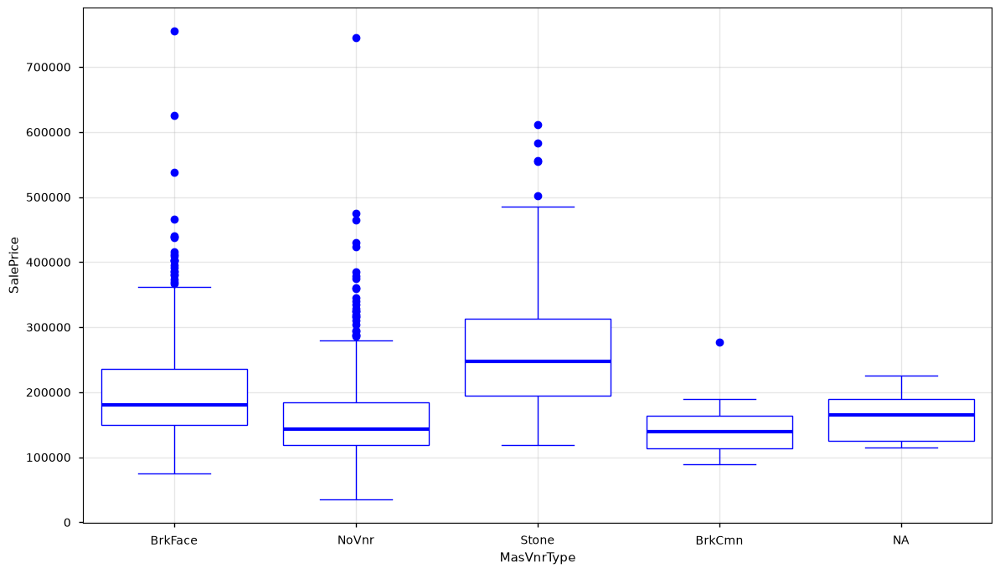

In [30]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='MasVnrType',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('MasVnrType')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

Самый дешевый и лишенных больших выбросов кирпич это Обычный кирпич, заполним пропуски им, так же проранжируем их от 0 до 2, где 0 - нет облицовки и BrkCmn (так как у них схожая статистика относительно цены), 1 - BrkFace, 2 - Stone, можно посмотреть что примерно большая часть где данные не заполненны, находится в том же ценовом диапазоне, что и дома с Облицовочным кирпичом, поэтому строки где есть площадь облицовки и нет типа, будем заполнять BrkFace

In [31]:
data.loc[data['MasVnrType'] == 'NoTypeVnr','MasVnrType'] = 'BrkFace'
data['MasVnrType'].astype('category')
data['MasVnrType'].value_counts()

MasVnrType
NoVnr      867
BrkFace    445
Stone      128
BrkCmn      15
NA           5
Name: count, dtype: int64

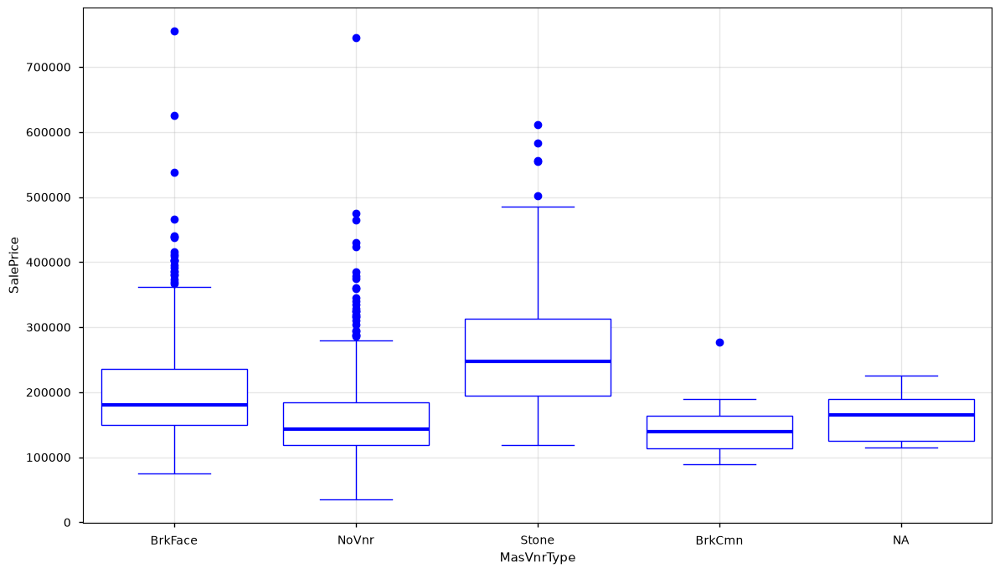

In [32]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='MasVnrType',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('MasVnrType')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

Превратим столбец в ранговую перемнную, оценив ценность отделки в соотвествии с графиком, как мы видим камень находится примерно в том же ценовом диапазоен что и отсутсвие отделки, так что дадим им одинаковые значения

In [33]:
data['MasVnrType'].replace(['NoVnr','BrkCmn','BrkFace','Stone'],[0,0,1,2],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\3282086826.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['MasVnrType'].replace(['NoVnr','BrkCmn','BrkFace','Stone'],[0,0,1,2],inplace=True)


## Basement признаки
    BsmtQual          37
    BsmtCond          37
    BsmtExposure      38
    BsmtFinType1      37
    BsmtFinType2      38

Отметим что почему то в одних признаках на 1 пропуск больше чем в других, можно посмотреть этот случай

Посмотрим строки, где пропуски есть не во всех пяти признаках:

In [34]:
cols = [
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2'
]
mask = data[cols].isna()

data.loc[
    mask.any(axis=1) & ~mask.all(axis=1),
    cols
]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
332,Gd,TA,No,GLQ,NaN
948,Gd,TA,NaN,Unf,Unf


В данных случаях видим что подвал есть, просто наличествуют пропуски в данных

In [35]:
data.loc[948, 'BsmtExposure'] = 'No'
data.loc[332,'BsmtFinType2'] = 'Unf'

Заменив точечно пропуски, можем теперь проверить остальные значения, и удостовериться, что в оставшихся строках пропуски во всех позициях, что может свидетельствовать о том, что подвала нет и мы можем проставить NA

In [36]:
data[cols] = data[cols].fillna('NA')

Переведем категориальные перменные в ранговые

In [37]:
data['BsmtQual'].replace(['Ex','Gd','TA','Fa','Po','NA'],[5,4,3,2,1,0],inplace=True)
data['BsmtCond'].replace(['Ex','Gd','TA','Fa','Po','NA'],[5,4,3,2,1,0],inplace=True)
data['BsmtExposure'].replace(['Gd','Av','Mn','No','NA'],[4,3,2,1,0],inplace=True)
data['BsmtFinType1'].replace(['GLQ','ALQ','BLQ','Rec','LwQ','Unf','NA'],[6,5,4,3,2,1,0],inplace=True)
data['BsmtFinType2'].replace(['GLQ','ALQ','BLQ','Rec','LwQ','Unf','NA'],[6,5,4,3,2,1,0],inplace=True)


C:\Users\user\AppData\Local\Temp\ipykernel_21328\141379188.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['BsmtQual'].replace(['Ex','Gd','TA','Fa','Po','NA'],[5,4,3,2,1,0],inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_21328\141379188.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', Tr

## Electrical
Посмотрим распределение цен относительно типа электрической системы, и укажем максимально соотвествующуб ценовомому диапазону дома

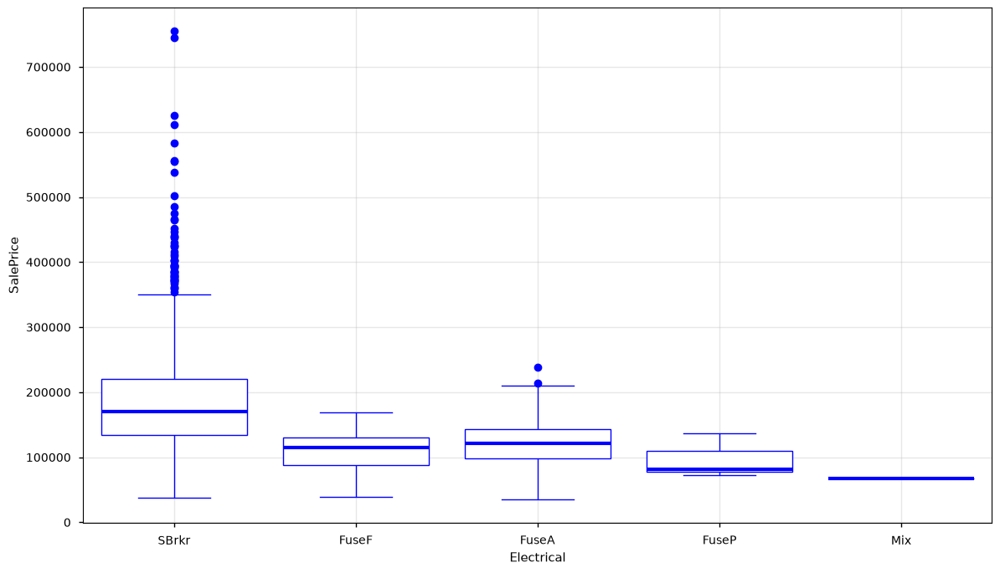

In [38]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='Electrical',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('Electrical')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

In [39]:
data.loc[(data['Electrical'].isna())]['SalePrice']

1379    167500
Name: SalePrice, dtype: int64

Дом лучше всего попадает в распределение домов с самой распостраненной системой, ею и заполним

In [40]:
data['Electrical'] = data['Electrical'].fillna('SBrkr')

Так как часть катагероий очень схожа по распредлению цен, то их можно совместить в одну

In [41]:
mapping = {
    'Mix': 'Other',
    'FuseP': 'Fuse',
    'FuseF': 'Fuse',
    'FuseA': 'Fuse',
    'SBrkr': 'CircuitBreaker'
}

data['Electrical'] = data['Electrical'].map(mapping)

## FireplaceQu
    FireplaceQu      690
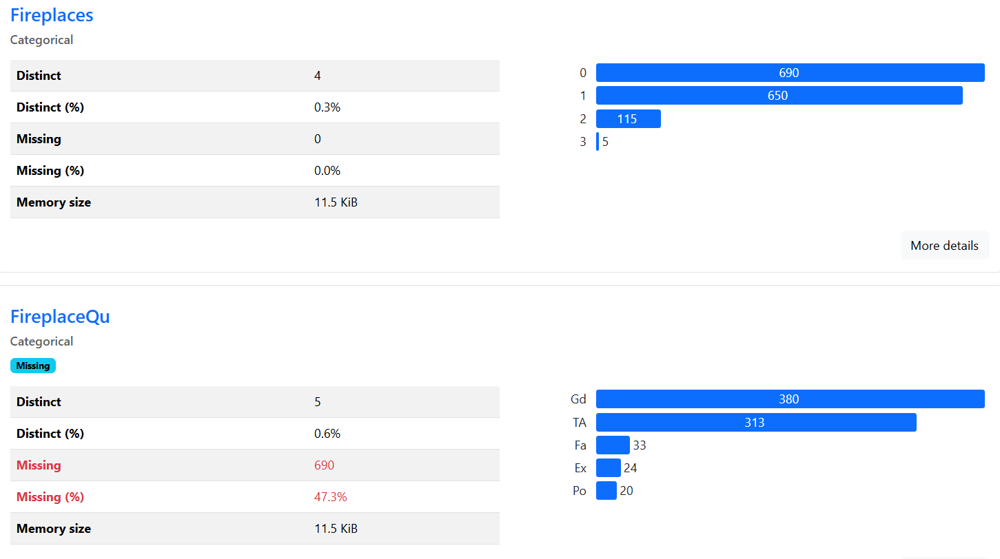
    
    Кол-во каминов идеально совпадает с пропусками

In [42]:
data['FireplaceQu'] = data['FireplaceQu'].fillna('NA')


In [43]:
data['FireplaceQu'].replace(['Ex','Gd','TA','Fa','Po','NA'],[5,4,3,2,1,0],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\4114134843.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['FireplaceQu'].replace(['Ex','Gd','TA','Fa','Po','NA'],[5,4,3,2,1,0],inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_21328\4114134843.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

## Garage признаки
    GarageType        81
    GarageYrBlt       81
    GarageFinish      81
    GarageQual        81
    GarageCond        81

Посмтрим есть ли строки где пропуски не во всех 5 признаках

In [44]:
cols = [
    'GarageType',
    'GarageYrBlt',
    'GarageFinish',
    'GarageQual',
    'GarageCond'
]
mask = data[cols].isna()

data.loc[
    mask.any(axis=1) & ~mask.all(axis=1),
    cols
]

,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond


Соответсвенно все пропуски обозначают отсутсвие гаража и их можно заменить на NA, и пока на 0 в годе постройки гаража

In [45]:
data[['GarageType','GarageFinish','GarageQual','GarageCond']] = data[['GarageType','GarageFinish','GarageQual','GarageCond']].fillna('NA')

In [46]:
data[['GarageType','GarageFinish','GarageQual','GarageCond']].isnull().sum().sort_values(ascending=False)

GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
dtype: int64

In [47]:
data['GarageYrBlt'] = data['GarageYrBlt'].fillna(data['YearBuilt'])

## PoolQC

In [48]:
data['PoolQC'] = data['PoolQC'].fillna('NA')
data['PoolQC'].replace(['Ex','Gd','Fa','NA'],[5,4,2,0],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\1926788203.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['PoolQC'].replace(['Ex','Gd','Fa','NA'],[5,4,2,0],inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_21328\1926788203.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['P

## Fence

In [49]:
data['Fence'] = data['Fence'].fillna('NoFence')

In [50]:
data[['Fence']].isnull().sum().sort_values(ascending=False)

Fence    0
dtype: int64

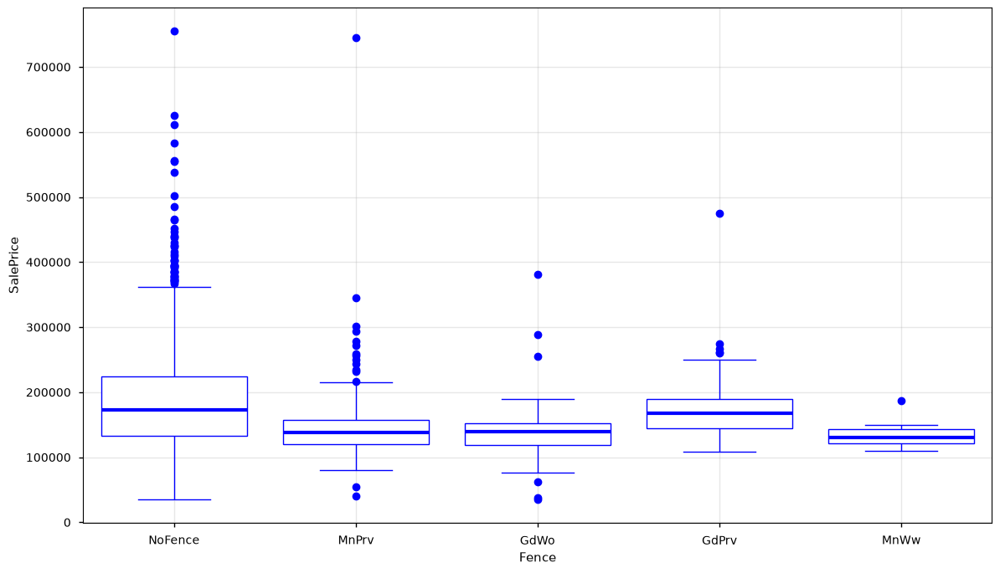

In [51]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='Fence',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('Fence')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

Все ограждения плюс минус одинаковые по разбросу цены, поэтому переменную нельзя назвать ординальной, поэтому будем кодировать ван - хот энкодером

## MiscFeature

In [52]:
data['MiscFeature'] = data['MiscFeature'].fillna('NA')

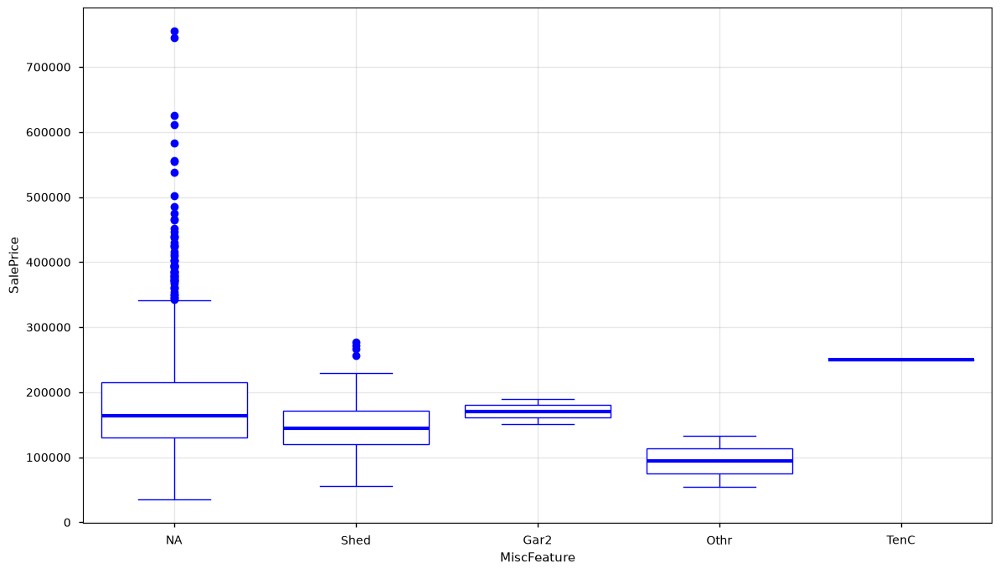

In [53]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=data,
    x='MiscFeature',
    y='SalePrice',
    color='white',
    boxprops={'edgecolor': 'blue'},
    whiskerprops={'color': 'blue'},
    capprops={'color': 'blue'},
    medianprops={'color': 'blue', 'linewidth': 3},
    flierprops={
        'marker': 'o',
        'markerfacecolor': 'blue',
        'markeredgecolor': 'blue',
        'markersize': 6
    }
)

plt.xlabel('MiscFeature')
plt.ylabel('SalePrice')
plt.grid(alpha=0.3)
plt.show()

Тож все значения плюс минус равнопраны, так же закодирую ван - хотом

Проверим не осталось ли пропусков

In [54]:
nulls = data.isnull().sum()
nulls = nulls[nulls != 0]
nulls

Series([], dtype: int64)

Теперь надо обработать остальные ординальные переменные

In [55]:
ordinal_mapping = {
    # Доступность инженерных коммуникаций
    'Utilities': {
        'ELO': 0,
        'NoSeWa': 1,
        'NoSewr': 2,
        'AllPub': 3
    },
    # Уклон участка: от крутого к небольшому
    'LandSlope': {
        'Sev': 0,
        'Mod': 1,
        'Gtl': 2
    },
    # Качество наружной отделки
    'ExterQual': {
        'Po': 0,
        'Fa': 1,
        'TA': 2,
        'Gd': 3,
        'Ex': 4
    },
    # Состояние наружной отделки
    'ExterCond': {
        'Po': 0,
        'Fa': 1,
        'TA': 2,
        'Gd': 3,
        'Ex': 4
    },
   # Качество отопления
    'HeatingQC': {
        'Po': 0,
        'Fa': 1,
        'TA': 2,
        'Gd': 3,
        'Ex': 4
    },
    # Качество кухни
    'KitchenQual': {
        'Po': 0,
        'Fa': 1,
        'TA': 2,
        'Gd': 3,
        'Ex': 4
    },
    # Функциональность дома
    'Functional': {
        'Sal': 0,
        'Sev': 1,
        'Maj2': 2,
        'Maj1': 3,
        'Mod': 4,
        'Min2': 5,
        'Min1': 6,
        'Typ': 7
    },
    # Степень отделки гаража
    'GarageFinish': {
        'NA': 0,
        'Unf': 1,
        'RFn': 2,
        'Fin': 3
    },
    # Качество гаража
    'GarageQual': {
        'NA': 0,
        'Po': 1,
        'Fa': 2,
        'TA': 3,
        'Gd': 4,
        'Ex': 5
    },
    # Состояние гаража
    'GarageCond': {
        'NA': 0,
        'Po': 1,
        'Fa': 2,
        'TA': 3,
        'Gd': 4,
        'Ex': 5
    },
}

In [56]:
for col, mapping in ordinal_mapping.items():
    if col in data.columns:
        data[col] = data[col].map(mapping)

In [57]:
data.isna().sum().sort_values(ascending=False)

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
MoSold           0
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
Length: 81, dtype: int64

### Обработка времеенных переменных

In [58]:
time_features = ['MoSold','YrSold','YearBuilt','YearRemodAdd','GarageYrBlt']
data[time_features].dtypes

MoSold            int64
YrSold            int64
YearBuilt         int64
YearRemodAdd      int64
GarageYrBlt     float64
dtype: object

После кризиса 2007 года, цены на жилье упали, что можно заметить по графику внизу

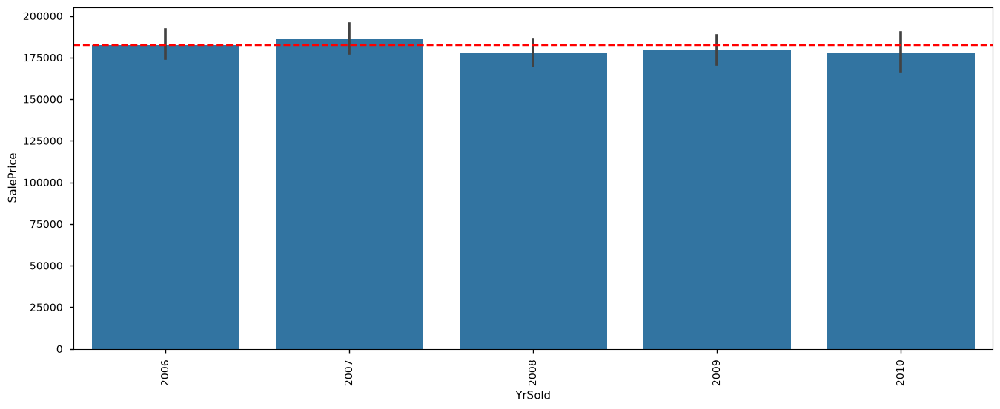

In [59]:
mean_2006 = data.loc[data['YrSold'] == 2006, 'SalePrice'].mean()
plt.figure(figsize=(16, 6))

sns.barplot(
    x='YrSold',
    y='SalePrice',
    data=data
)

plt.axhline(
    y=mean_2006,
    color='red',
    linestyle='--',
    label='Средняя цена за 2006 год'
)

plt.xticks(rotation=90)
plt.show()

Чтобы передать эту тенденцию модели, мы передадим в нее, как числовой год, так и ван - хот вектор года

<Axes: xlabel='YearBuilt', ylabel='SalePrice'>

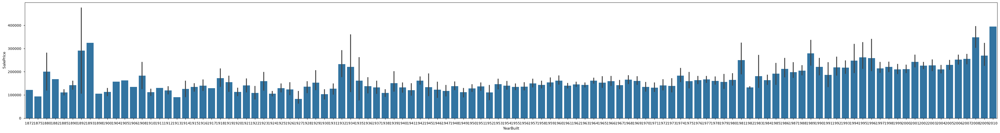

In [60]:
plt.figure(figsize=(50, 6))

sns.barplot(
    x='YearBuilt',
    y='SalePrice',
    data=data
)

<Axes: xlabel='YearRemodAdd', ylabel='SalePrice'>

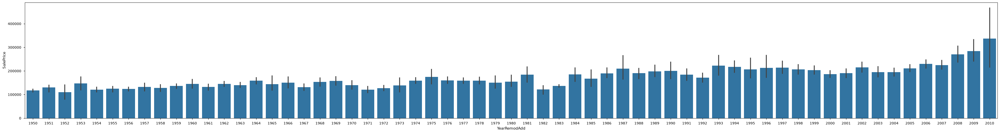

In [61]:
plt.figure(figsize=(50, 6))

sns.barplot(
    x='YearRemodAdd',
    y='SalePrice',
    data=data
)

Как можно увидеть из графиков, у года реконструкции налюдется более явный тренд увеличения цен, так что стоит расчитать два признака - возраст дома и количество лет с реконструкции

### Остальные категориальные переменные закодируем ван-хоттом

In [62]:
data.select_dtypes(include=['object', 'string']).columns.tolist()

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'LotConfig',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'Foundation',
 'Heating',
 'CentralAir',
 'Electrical',
 'GarageType',
 'PavedDrive',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

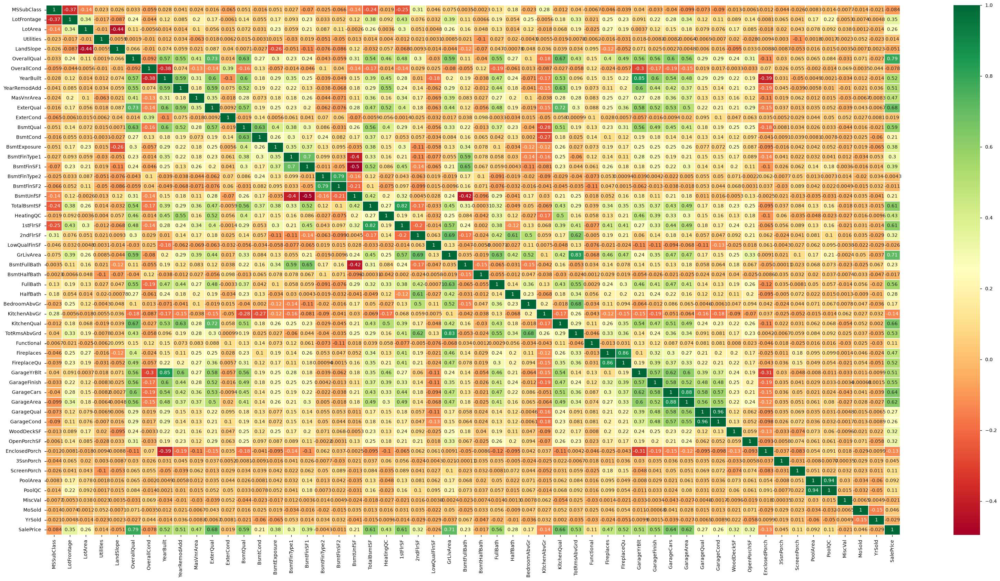

In [63]:
sns.heatmap(data.drop(columns=['Id']).corr(numeric_only = 'True'),annot=True,cmap='RdYlGn',linewidths=0.2,xticklabels=1,yticklabels=1) #df.corr()-->correlation matrix
fig=plt.gcf()
fig.set_size_inches(40,20)
plt.show()

In [64]:
data.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
ExterQual        0.682639
KitchenQual      0.659600
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
BsmtQual         0.585207
FullBath         0.560664
GarageFinish     0.549247
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
FireplaceQu      0.520438
GarageYrBlt      0.508043
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
HeatingQC        0.427649
BsmtFinSF1       0.386420
BsmtExposure     0.375045
LotFrontage      0.349876
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
BsmtFinType1     0.304908
HalfBath         0.284108
GarageQual       0.273839
LotArea          0.263843
GarageCond       0.263191
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BsmtCond         0.212607
BedroomAbvGr     0.168213
PoolQC           0.111696
ScreenPorch      0.111447
Functional       0.107619
PoolArea    

Выведем сильно скорелированные пары

In [65]:
threshold = 0.8

corr = data.corr(numeric_only=True)

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]

        if abs(r) >= threshold:
            print(f'{corr.columns[i]} — {corr.columns[j]}: {r:.3f}')

YearBuilt — GarageYrBlt: 0.845
TotalBsmtSF — 1stFlrSF: 0.820
GrLivArea — TotRmsAbvGrd: 0.825
Fireplaces — FireplaceQu: 0.863
GarageCars — GarageArea: 0.882
GarageQual — GarageCond: 0.959
PoolArea — PoolQC: 0.937


In [66]:
data['CentralAir'].replace(['Y','N'],[1,0],inplace=True)
data['Street'].replace(['Pave','Grvl'],[1,0],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\263728725.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['CentralAir'].replace(['Y','N'],[1,0],inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_21328\263728725.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['CentralAir'].re

## Feature Engeneering

In [67]:
cat_features = ['MSSubClass','MSZoning','Alley','LotConfig','LandContour','Neighborhood','BldgType','HouseStyle','RoofStyle','RoofMatl','Exterior1st','Foundation','Heating','Condition1','Condition2','Exterior2nd','GarageType','PavedDrive','Fence','MiscFeature','SaleType','SaleCondition','LotShape','Electrical'] #сделано
discrete_feature = ['FullBath','TotRmsAbvGrd','GarageCars','Fireplaces','BedroomAbvGr','KitchenAbvGr'] #сделано
rang_features = ['Utilities','OverallQual','OverallCond','ExterQual','ExterCond','BsmtQual','BsmtCond','BsmtFinType1','BsmtFinType2','HeatingQC','KitchenQual','FireplaceQu','GarageFinish','GarageQual','GarageCond','PoolQC','Functional','LandSlope','MasVnrType','BsmtExposure'] #сделано
binary_features = ['CentralAir','Street','BsmtHalfBath','BsmtFullBath','HalfBath','Pool','OpenPorch','EnclosedPorch','3SsnPorch','ScreenPorch','LowQualFin','BsmtFin'] #сделано
continuous_feature = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF','MiscVal'] #сделано
date_features = ['MoSold','YrSold']
to_drop = ['Id','LowQualFinSF','BsmtFinSF2','PoolArea','YearBuilt','YearRemodAdd','GarageYrBlt']
target = 'SalePrice'

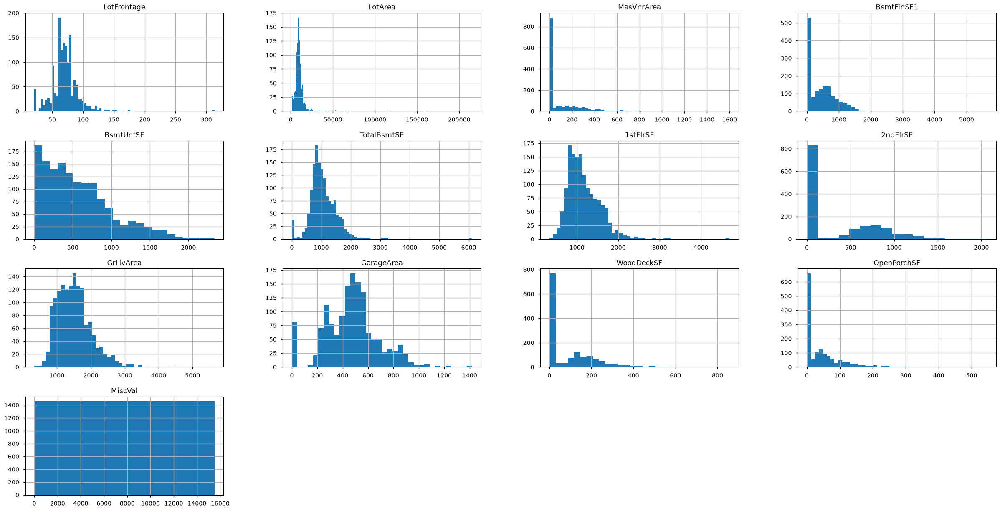

In [68]:
data[continuous_feature].hist(figsize=(30, 15),bins='fd')
plt.show()

## BsmtHalfBath и BsmtFullBath и HalfBath
Заменим количество санузлов на бинарный признак их наличия

In [69]:
data['BsmtHalfBath'].replace([0,1,2],[0,1,1],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\1631792138.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['BsmtHalfBath'].replace([0,1,2],[0,1,1],inplace=True)


In [70]:
data['BsmtFullBath'].replace([0,1,2,3],[0,1,1,1],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\4084225183.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['BsmtFullBath'].replace([0,1,2,3],[0,1,1,1],inplace=True)


In [71]:
data['HalfBath'].replace([0,1,2],[0,1,1],inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_21328\1850868474.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['HalfBath'].replace([0,1,2],[0,1,1],inplace=True)


## Pool
Чтобы модель не переучилась на малое кол-во уникальных значений, заменим площадь бассейна бинарным маркером его наличия

In [72]:
data['Pool'] = (data['PoolArea'] != 0).astype(int)

## EnclosedPorch и 3SsnPorch и ScreenPorch
Так как эти признаки очень расряжены то лучше их заменить на бинарные маркеры наличия такого типа веранды, так же добавим аналогичный признак для обычной веранды

In [73]:
data['EnclosedPorch'] = (data['EnclosedPorch'] != 0).astype(int)
data['3SsnPorch'] = (data['3SsnPorch'] != 0).astype(int)
data['ScreenPorch'] = (data['ScreenPorch'] != 0).astype(int)
data['OpenPorch'] = (data['OpenPorchSF'] != 0).astype(int)

## LowQualFinSF и BsmtFinSF2
Тоже сделаем эти фичи бинарными

In [74]:
data['LowQualFin'] = (data['LowQualFinSF'] != 0).astype(int)
data['BsmtFin'] = (data['BsmtFinSF2'] != 0).astype(int)

## Попробуем логарифмировать непрерывные переменные
Это поможет снизить разрывы между между данными

In [75]:
log_continious_features = []
for feature in continuous_feature:
    data[f'{feature}_log'] = np.log1p(data[feature])
    log_continious_features.append(f'{feature}_log')

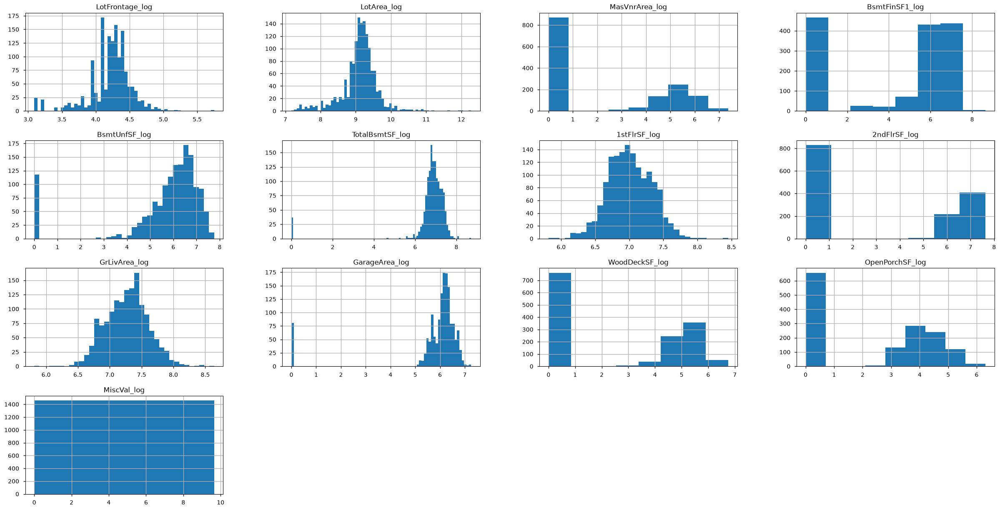

In [76]:
data[log_continious_features].hist(figsize=(30, 15),bins='fd')
plt.show()

## Попробуем так же логарифмировать целевую переменную, чтобы лучше апроксимировать нашу зависимость

<Axes: >

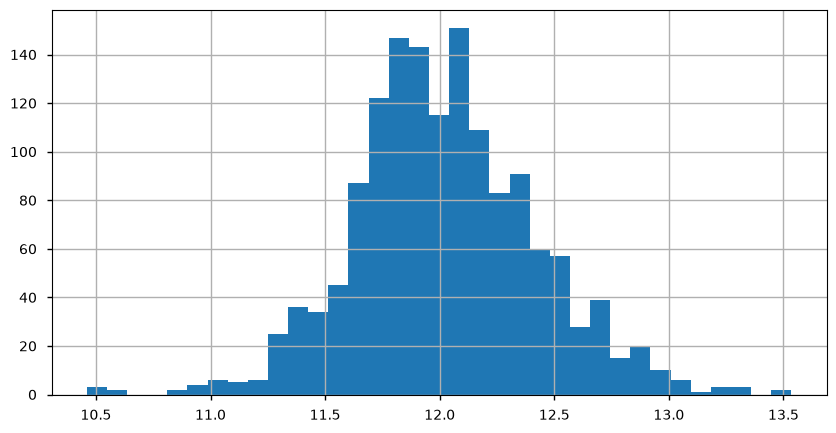

In [77]:
data[f'{target}_log'] = np.log1p(data[target])
data[f'{target}_log'].hist(figsize=(10, 5),bins='fd')

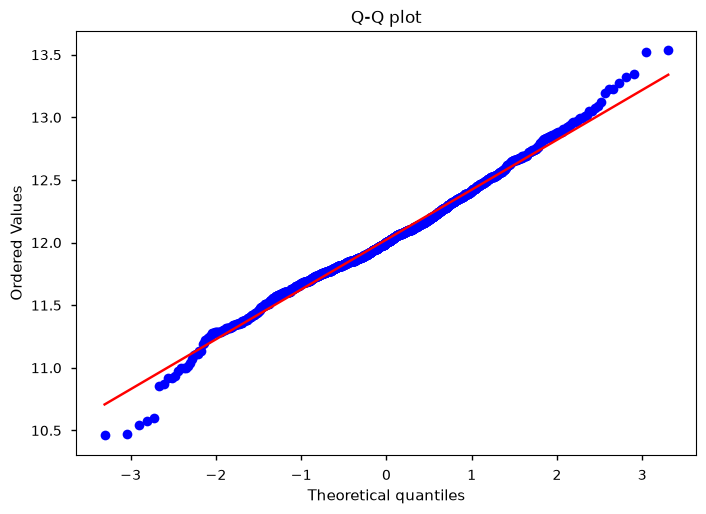

In [78]:
stats.probplot(data['SalePrice_log'], dist="norm", plot=plt)
plt.title("Q-Q plot")
plt.show()

После логарифического преобразования распределение таргета стало близко к нормальному, что хорошо

In [79]:
data.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

Посмотрим насколько явной стала наша зависимость

In [80]:
def draw_dependence(x,y):

    fig, axes = plt.subplots(1, 4, figsize=(14, 5))

    sns.regplot(
        data=data,
        x=x,
        y=y,
        ax=axes[0],
        scatter_kws={'alpha': 0.3}
    )

    sns.regplot(
        data=data,
        x=x + '_log',
        y=y,
        ax=axes[1],
        scatter_kws={'alpha': 0.3}
    )

    sns.regplot(
        data=data,
        x=x + '_log',
        y=y + '_log',
        ax=axes[2],
        scatter_kws={'alpha': 0.3}
    )

    sns.regplot(
        data=data,
        x=x,
        y=y + '_log',
        ax=axes[3],
        scatter_kws={'alpha': 0.3}
    )

    axes[0].set_title(f'Исходная {x}')
    axes[1].set_title(f'Логарифм {x}')
    axes[2].set_title(f'Логарифмы {x} и {y}')
    axes[3].set_title(f'{x} и логарифм {y}')
    plt.show()

    # slope, intercept, r_value, p_value, std_err = stats.linregress(data[x], data[y])
    # result.append({'name': f'Исходная {x}',
    #                 "Коэффициент корреляции (r)" : f"{r_value:.3f}",
    #                 "Коэффициент детерминации (R²)" : f"{r_value**2:.3f}",
    #                 "p-value" : f"{p_value:.5f}"
    #                 })
    
    # print(f"Коэффициент корреляции (r): {r_value:.3f}")
    # print(f"Коэффициент детерминации (R²): {r_value**2:.3f}")
    # print(f"p-value: {p_value:.5f}")
    # print("--------------------------------------------------------------------------------")

    # slope, intercept, r_value, p_value, std_err = stats.linregress(data[x + '_log'], data[y])
    # result.append({'name': f'Логарифм {x}',
    #                 "Коэффициент корреляции (r)" : f"{r_value:.3f}",
    #                 "Коэффициент детерминации (R²)" : f"{r_value**2:.3f}",
    #                 "p-value" : f"{p_value:.5f}"
    #                 })
    
    # print(f"Коэффициент корреляции (r): {r_value:.3f}")
    # print(f"Коэффициент детерминации (R²): {r_value**2:.3f}")
    # print(f"p-value: {p_value:.5f}")
    # print("--------------------------------------------------------------------------------")

    slope, intercept, r_value_logx, p_value_logx, std_err = stats.linregress(data[x + '_log'], data[y + '_log'])

    print(f'Логарифм {x} и {y}')
    print(f"Коэффициент корреляции (r): {r_value_logx:.3f}")
    print(f"Коэффициент детерминации (R²): {r_value_logx**2:.3f}")
    print(f"p-value: {p_value_logx:.5f}")
    print("--------------------------------------------------------------------------------")

    slope, intercept, r_value, p_value, std_err = stats.linregress(data[x], data[y + '_log'])

    print(f'{x} и логарифм {y}')
    print(f"Коэффициент корреляции (r): {r_value:.3f}")
    print(f"Коэффициент детерминации (R²): {r_value**2:.3f}")
    print(f"p-value: {p_value:.5f}")
    print("--------------------------------------------------------------------------------")

    if p_value_logx > 0 and p_value > 0:
        if p_value_logx > p_value:
            return x + '_log'
        else:
            return x
    elif p_value_logx < 0 and p_value < 0:
        if p_value_logx < p_value:
            return x + '_log'
        else:
            return x
    else:
        if p_value_logx > p_value:
            return x + '_log'
        else:
            return x

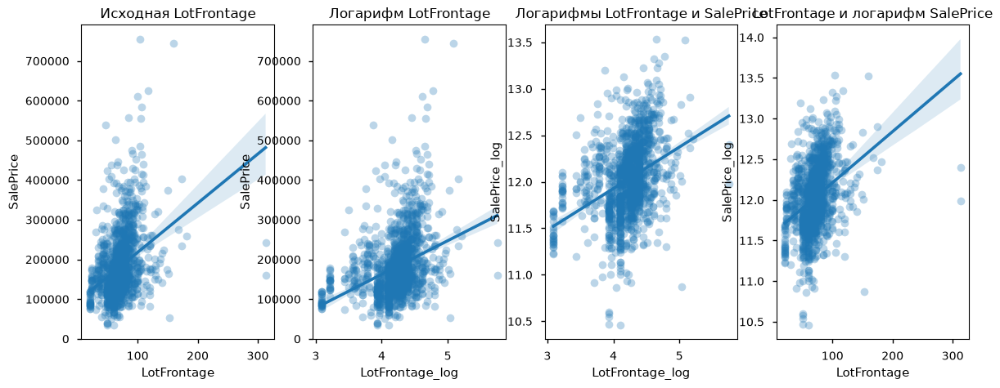

Логарифм LotFrontage и SalePrice
Коэффициент корреляции (r): 0.362
Коэффициент детерминации (R²): 0.131
p-value: 0.00000
--------------------------------------------------------------------------------
LotFrontage и логарифм SalePrice
Коэффициент корреляции (r): 0.353
Коэффициент детерминации (R²): 0.125
p-value: 0.00000
--------------------------------------------------------------------------------


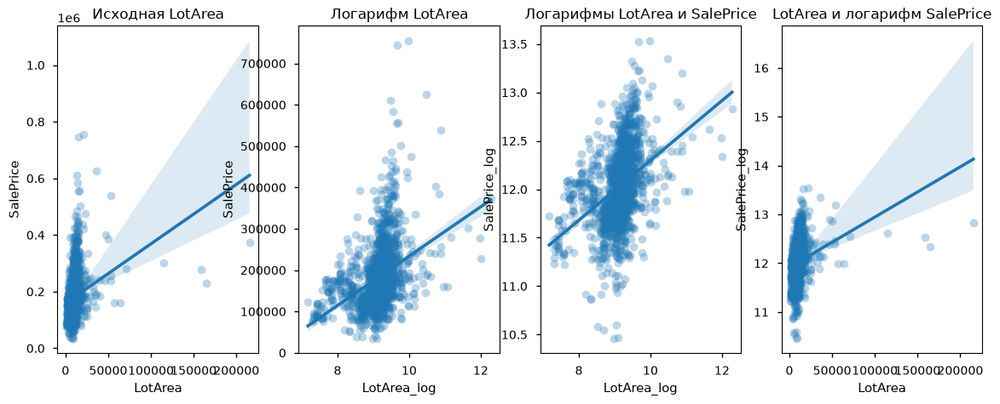

Логарифм LotArea и SalePrice
Коэффициент корреляции (r): 0.400
Коэффициент детерминации (R²): 0.160
p-value: 0.00000
--------------------------------------------------------------------------------
LotArea и логарифм SalePrice
Коэффициент корреляции (r): 0.257
Коэффициент детерминации (R²): 0.066
p-value: 0.00000
--------------------------------------------------------------------------------


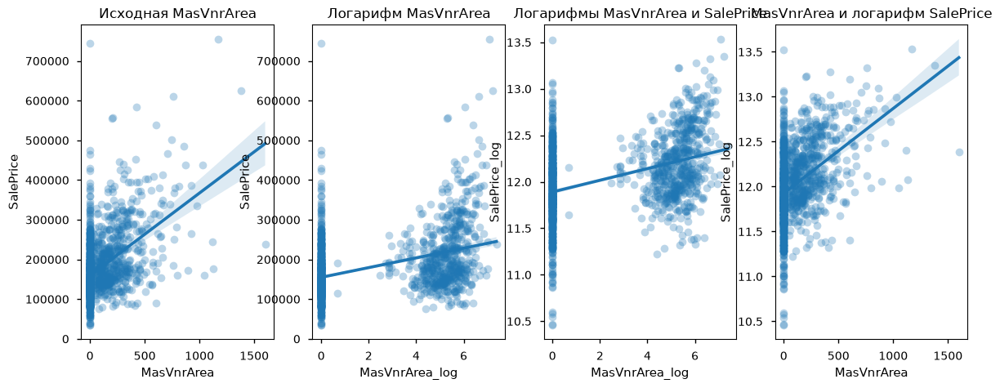

Логарифм MasVnrArea и SalePrice
Коэффициент корреляции (r): 0.413
Коэффициент детерминации (R²): 0.171
p-value: 0.00000
--------------------------------------------------------------------------------
MasVnrArea и логарифм SalePrice
Коэффициент корреляции (r): 0.427
Коэффициент детерминации (R²): 0.182
p-value: 0.00000
--------------------------------------------------------------------------------


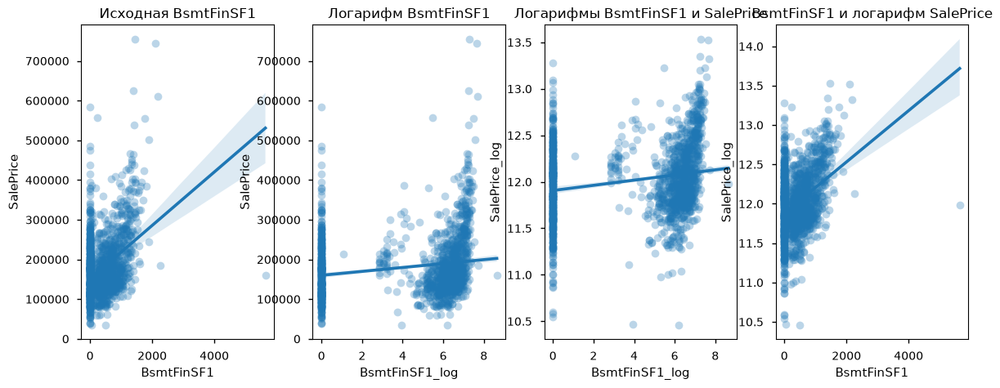

Логарифм BsmtFinSF1 и SalePrice
Коэффициент корреляции (r): 0.208
Коэффициент детерминации (R²): 0.043
p-value: 0.00000
--------------------------------------------------------------------------------
BsmtFinSF1 и логарифм SalePrice
Коэффициент корреляции (r): 0.372
Коэффициент детерминации (R²): 0.138
p-value: 0.00000
--------------------------------------------------------------------------------


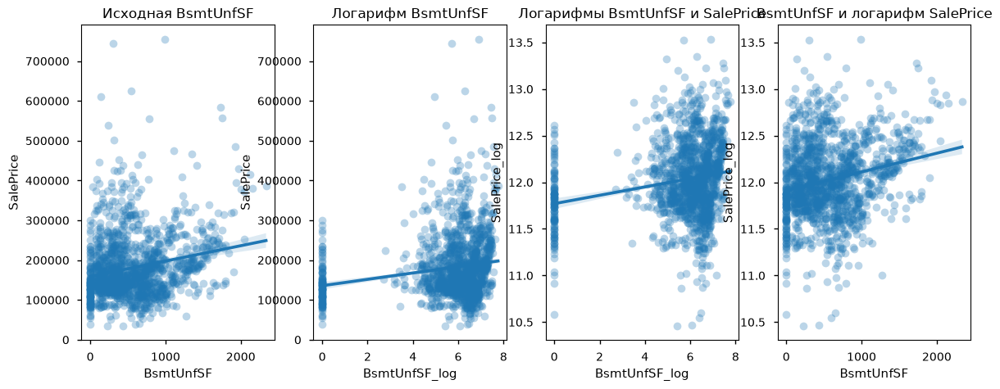

Логарифм BsmtUnfSF и SalePrice
Коэффициент корреляции (r): 0.208
Коэффициент детерминации (R²): 0.043
p-value: 0.00000
--------------------------------------------------------------------------------
BsmtUnfSF и логарифм SalePrice
Коэффициент корреляции (r): 0.222
Коэффициент детерминации (R²): 0.049
p-value: 0.00000
--------------------------------------------------------------------------------


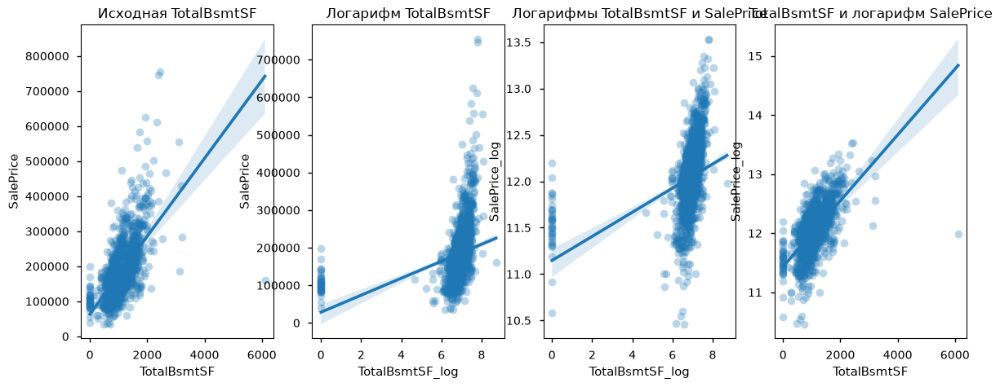

Логарифм TotalBsmtSF и SalePrice
Коэффициент корреляции (r): 0.373
Коэффициент детерминации (R²): 0.139
p-value: 0.00000
--------------------------------------------------------------------------------
TotalBsmtSF и логарифм SalePrice
Коэффициент корреляции (r): 0.612
Коэффициент детерминации (R²): 0.375
p-value: 0.00000
--------------------------------------------------------------------------------


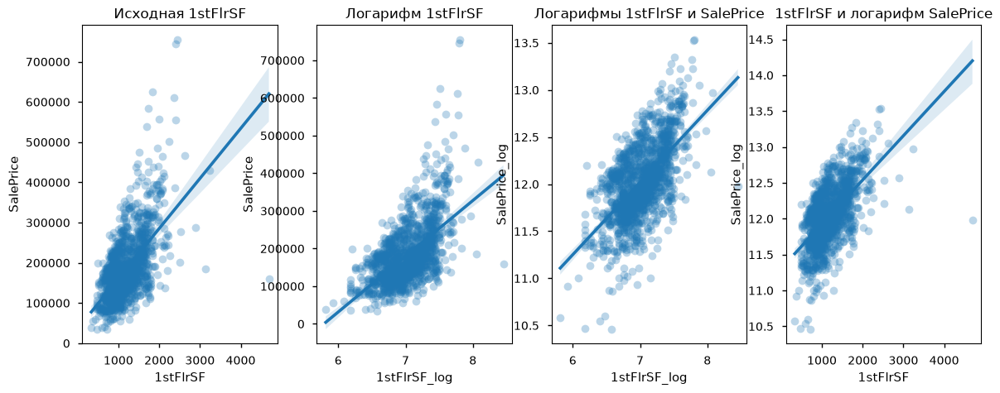

Логарифм 1stFlrSF и SalePrice
Коэффициент корреляции (r): 0.609
Коэффициент детерминации (R²): 0.371
p-value: 0.00000
--------------------------------------------------------------------------------
1stFlrSF и логарифм SalePrice
Коэффициент корреляции (r): 0.597
Коэффициент детерминации (R²): 0.356
p-value: 0.00000
--------------------------------------------------------------------------------


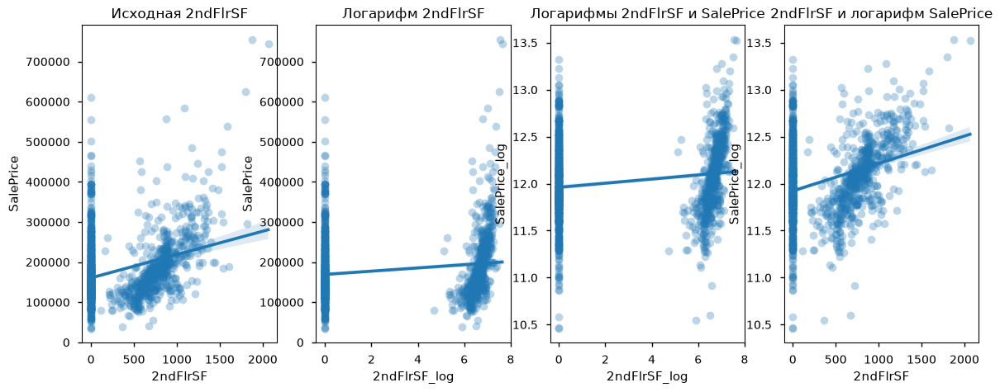

Логарифм 2ndFlrSF и SalePrice
Коэффициент корреляции (r): 0.181
Коэффициент детерминации (R²): 0.033
p-value: 0.00000
--------------------------------------------------------------------------------
2ndFlrSF и логарифм SalePrice
Коэффициент корреляции (r): 0.319
Коэффициент детерминации (R²): 0.102
p-value: 0.00000
--------------------------------------------------------------------------------


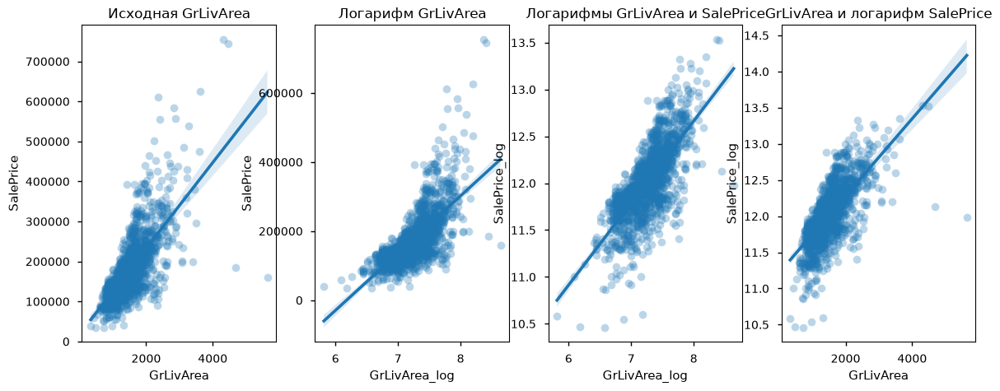

Логарифм GrLivArea и SalePrice
Коэффициент корреляции (r): 0.730
Коэффициент детерминации (R²): 0.533
p-value: 0.00000
--------------------------------------------------------------------------------
GrLivArea и логарифм SalePrice
Коэффициент корреляции (r): 0.701
Коэффициент детерминации (R²): 0.491
p-value: 0.00000
--------------------------------------------------------------------------------


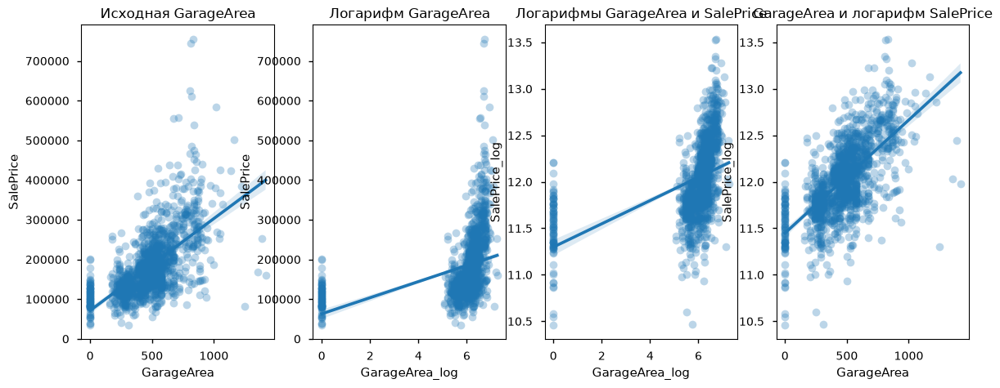

Логарифм GarageArea и SalePrice
Коэффициент корреляции (r): 0.455
Коэффициент детерминации (R²): 0.207
p-value: 0.00000
--------------------------------------------------------------------------------
GarageArea и логарифм SalePrice
Коэффициент корреляции (r): 0.651
Коэффициент детерминации (R²): 0.424
p-value: 0.00000
--------------------------------------------------------------------------------


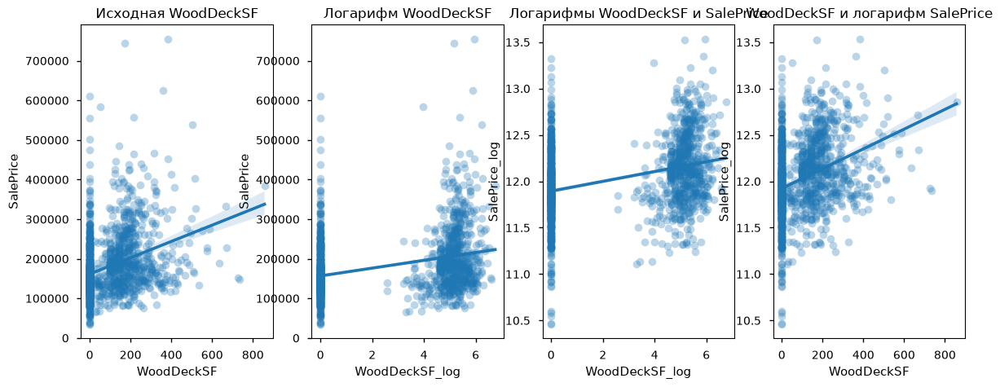

Логарифм WoodDeckSF и SalePrice
Коэффициент корреляции (r): 0.343
Коэффициент детерминации (R²): 0.118
p-value: 0.00000
--------------------------------------------------------------------------------
WoodDeckSF и логарифм SalePrice
Коэффициент корреляции (r): 0.334
Коэффициент детерминации (R²): 0.112
p-value: 0.00000
--------------------------------------------------------------------------------


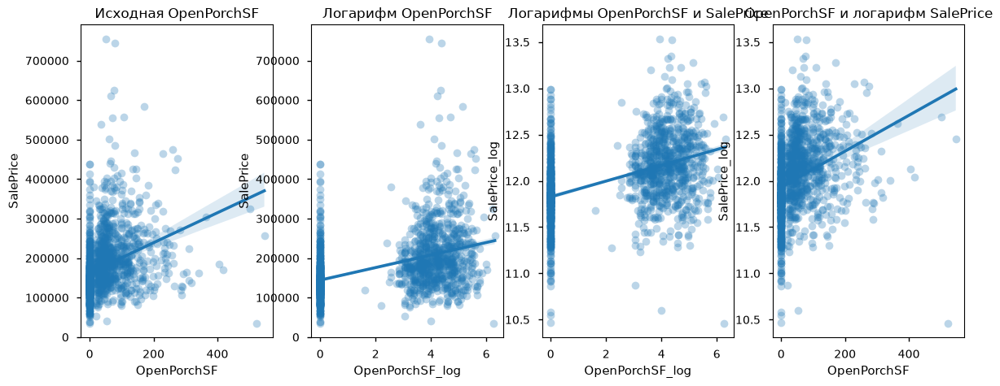

Логарифм OpenPorchSF и SalePrice
Коэффициент корреляции (r): 0.460
Коэффициент детерминации (R²): 0.212
p-value: 0.00000
--------------------------------------------------------------------------------
OpenPorchSF и логарифм SalePrice
Коэффициент корреляции (r): 0.321
Коэффициент детерминации (R²): 0.103
p-value: 0.00000
--------------------------------------------------------------------------------


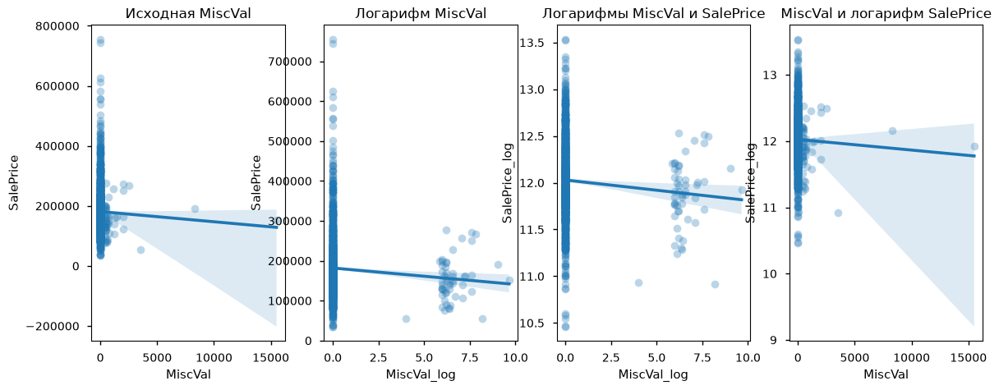

Логарифм MiscVal и SalePrice
Коэффициент корреляции (r): -0.067
Коэффициент детерминации (R²): 0.004
p-value: 0.01038
--------------------------------------------------------------------------------
MiscVal и логарифм SalePrice
Коэффициент корреляции (r): -0.020
Коэффициент детерминации (R²): 0.000
p-value: 0.44462
--------------------------------------------------------------------------------


In [81]:
results = []
for feature in continuous_feature:
    result = draw_dependence(feature, 'SalePrice')
    results.append(result)

Построим маленькие линейные регрессии по каждой переменной и посмотрим какая взаимосвязь лучше и отберем какие переменные лучше логарифмически преобразовывать а какие нет

In [82]:
final_continious_cols = results
final_continious_cols

['LotFrontage',
 'LotArea',
 'MasVnrArea_log',
 'BsmtFinSF1_log',
 'BsmtUnfSF_log',
 'TotalBsmtSF_log',
 '1stFlrSF',
 '2ndFlrSF_log',
 'GrLivArea',
 'GarageArea_log',
 'WoodDeckSF',
 'OpenPorchSF',
 'MiscVal']

## Создание признаков

#Age
- Age = YrSold - YearBuilt
- Age_from_Remod = YrSold - YearRemodAdd

#Quality
- OverallQual*OverallCond = OverallQual * OverallCond
- ExterQual*ExterCond = ExterQual * ExterCond
- OverallQual*GrLivArea = OverallQual * GrLivArea

#BasementQuality
- TotalBsmtSF*BsmtQual*BsmtCond = TotalBsmtSF * BsmtQual * BsmtCond
- BsmtFinType1*BsmtFinSF1*BsmtQual = BsmtFinType1 * BsmtFinSF1 * BsmtQual
- BsmtFinType2*BsmtFinSF2*BsmtQual = BsmtFinType2 * BsmtFinSF2 * BsmtQual
#OverallBath
- OverallBath = BsmtFullBath + BsmtHalfBath + BsmtFullBath

#Garage
- OverallGarage = GarageArea * GarageQual * GarageCond

In [83]:
# Age -> discrete
data["Age"] = data["YrSold"] - data["YearBuilt"]
data["Age_from_Remod"] = data["YrSold"] - data["YearRemodAdd"]

#TotalSquarefit -> continious
data["TotalSqFeet"] = data["GrLivArea"] + data["TotalBsmtSF"]
data["TotalSqFeet*OverallCond"] = data["TotalSqFeet"] * data["OverallCond"]

# Quality -> discrete
data["OverallQual*OverallCond"] = data["OverallQual"] * data["OverallCond"]
data["ExterQual*ExterCond"] = data["ExterQual"] * data["ExterCond"]
# data["OverallQual*GrLivArea"] = data["OverallQual"] * data["GrLivArea"]

# BasementQuality -> discrete
data["TotalBsmtSF*BsmtQual*BsmtCond"] = (
    data["TotalBsmtSF"] * data["BsmtQual"] * data["BsmtCond"]
)
data["BsmtFinType1*BsmtFinSF1*BsmtQual"] = (
    data["BsmtFinType1"] * data["BsmtFinSF1"] * data["BsmtQual"]
)
data["BsmtFinType2*BsmtFinSF2*BsmtQual"] = (
    data["BsmtFinType2"] * data["BsmtFinSF2"] * data["BsmtQual"]
)

# OverallBath -> discrete
data["OverallBath"] = (data["FullBath"] + data["HalfBath"] + data["BsmtFullBath"] + data["BsmtHalfBath"])
# Garage -> discrete
data["OverallGarage"] = (
    data["GarageArea"] * data["GarageQual"] * data["GarageCond"]
)
#Pool
data['PoolOverall'] = data["PoolQC"] * data["Pool"]
#Fireplace
data['Overall_Fireplaces'] = data['FireplaceQu'] * data['Fireplaces']

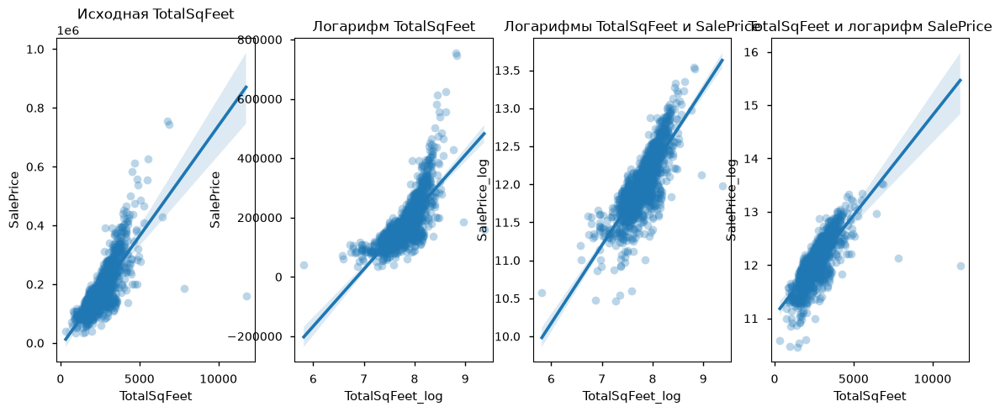

Логарифм TotalSqFeet и SalePrice
Коэффициент корреляции (r): 0.804
Коэффициент детерминации (R²): 0.646
p-value: 0.00000
--------------------------------------------------------------------------------
TotalSqFeet и логарифм SalePrice
Коэффициент корреляции (r): 0.773
Коэффициент детерминации (R²): 0.598
p-value: 0.00000
--------------------------------------------------------------------------------


In [84]:
data["TotalSqFeet_log"] = np.log1p(data["TotalSqFeet"])
result = draw_dependence("TotalSqFeet", 'SalePrice')

In [85]:
final_continious_cols.append("TotalSqFeet")

In [86]:
binary_features.remove("Pool")
rang_features.remove('PoolQC')

In [87]:
discrete_feature.remove("Fireplaces")
rang_features.remove('FireplaceQu')

In [88]:
complex_features = ["Age","Age_from_Remod","OverallQual*OverallCond","ExterQual*ExterCond","TotalBsmtSF*BsmtQual*BsmtCond","BsmtFinType1*BsmtFinSF1*BsmtQual","BsmtFinType2*BsmtFinSF2*BsmtQual","OverallBath","OverallGarage","TotalSqFeet*OverallCond",'PoolOverall','Overall_Fireplaces'] #для создаваемых фичей
final_target = ['SalePrice_log']

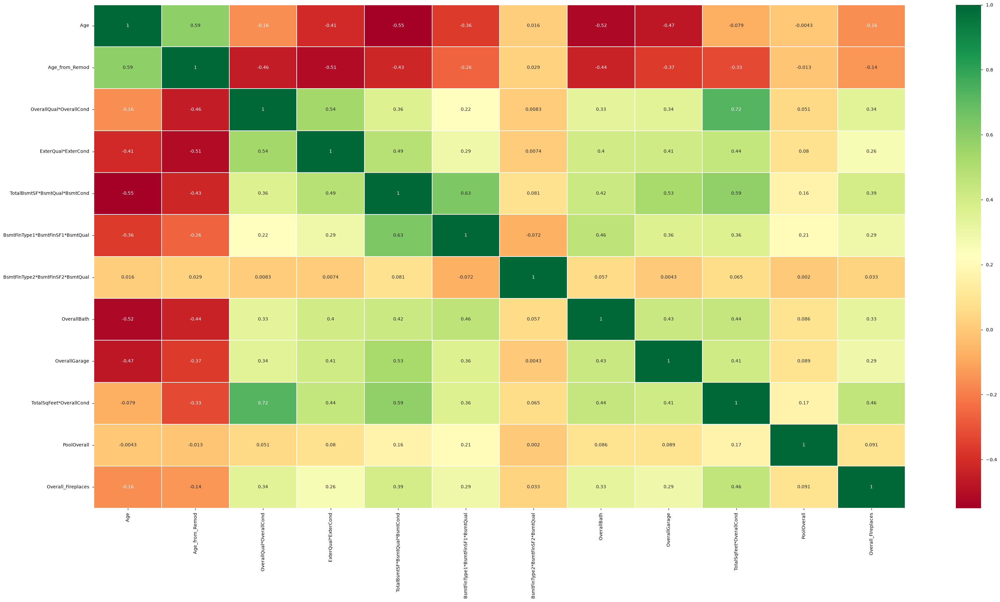

In [89]:
sns.heatmap(data[complex_features].corr(numeric_only = 'True'),annot=True,cmap='RdYlGn',linewidths=0.2,xticklabels=1,yticklabels=1) #df.corr()-->correlation matrix
fig=plt.gcf()
fig.set_size_inches(40,20)
plt.show()

In [90]:
threshold = 0.8

corr = data[complex_features].corr(numeric_only = 'True')

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]

        if abs(r) >= threshold:
            print(f'{corr.columns[i]} — {corr.columns[j]}: {r:.3f}')

Созданные фичи обладают хорошей корелляцией с лог таргетом

## Neighborhood

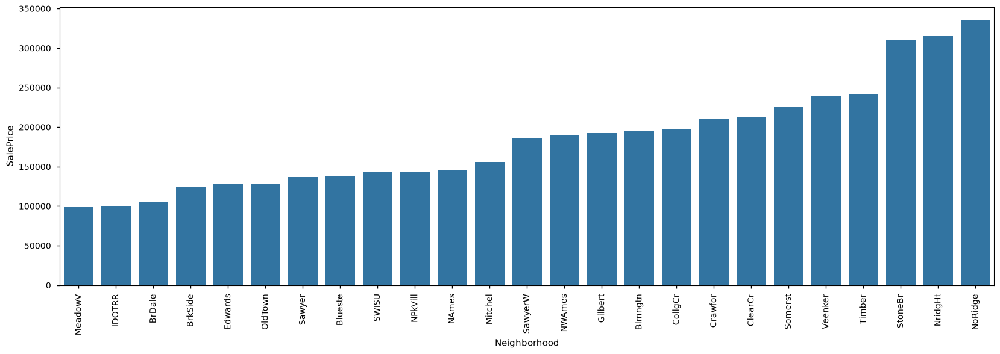

In [91]:
order = (
    data.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values()
    .index
)

plt.figure(figsize=(20, 6))

sns.barplot(
    x='Neighborhood',
    y='SalePrice',
    data=data,
    order=order,
    errorbar=None
)

plt.xticks(rotation=90)
plt.show()

Чтобы не сделать лик на кросс валидиации, я пока не буду использовать идею разбиения районов на 3 бина, так как это испортит интерпретацию скора на СV, поэтому для начала начнем с ван-хот кодирования, возможно буду ее читать во время кросс-валидации на оюучающей выборке, мб cделаю oof фичу по средней стоимости жилья в районе

## Финальная проверка кореляции

In [92]:
#Финальный перечень фичей
final_features = cat_features + discrete_feature + rang_features + binary_features + final_continious_cols + date_features + complex_features + final_target

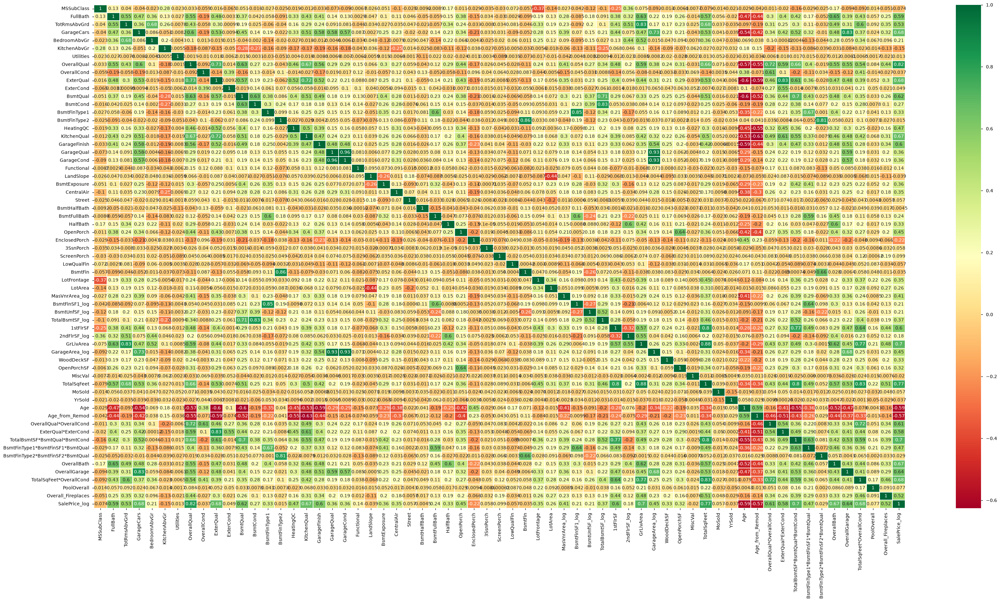

In [93]:
sns.heatmap(data[final_features].corr(numeric_only = 'True'),annot=True,cmap='RdYlGn',linewidths=0.2,xticklabels=1,yticklabels=1) #df.corr()-->correlation matrix
fig=plt.gcf()
fig.set_size_inches(40,20)
plt.show()

In [94]:
data[final_features].corr(numeric_only = 'True')['SalePrice_log'].sort_values(ascending=False).head(40)

SalePrice_log                       1.000000
OverallQual                         0.817185
TotalSqFeet                         0.773277
TotalBsmtSF*BsmtQual*BsmtCond       0.703306
GrLivArea                           0.700927
GarageCars                          0.680625
ExterQual                           0.678840
TotalSqFeet*OverallCond             0.676723
OverallBath                         0.672274
KitchenQual                         0.667893
OverallGarage                       0.636731
BsmtQual                            0.615804
OverallQual*OverallCond             0.606873
GarageFinish                        0.604878
1stFlrSF                            0.596981
FullBath                            0.594771
ExterQual*ExterCond                 0.577042
TotRmsAbvGrd                        0.534422
Overall_Fireplaces                  0.520190
HeatingQC                           0.473762
BsmtFinType1*BsmtFinSF1*BsmtQual    0.473470
GarageArea_log                      0.454898
OpenPorch 

In [95]:
threshold = 0.8

corr = data[final_features].corr(numeric_only = 'True')

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]

        if abs(r) >= threshold:
            print(f'{corr.columns[i]} — {corr.columns[j]}: {r:.3f}')

TotRmsAbvGrd — GrLivArea: 0.825
GarageCars — OverallGarage: 0.826
OverallQual — SalePrice_log: 0.817
ExterQual — ExterQual*ExterCond: 0.829
BsmtCond — TotalBsmtSF_log: 0.832
BsmtFinType1 — BsmtFinSF1_log: 0.853
BsmtFinType2 — BsmtFin: 0.863
BsmtFinType2 — BsmtFinType2*BsmtFinSF2*BsmtQual: 0.806
GarageQual — GarageCond: 0.959
GarageQual — GarageArea_log: 0.931
GarageCond — GarageArea_log: 0.930
GrLivArea — TotalSqFeet: 0.880
TotalSqFeet — TotalBsmtSF*BsmtQual*BsmtCond: 0.802
TotalSqFeet — TotalSqFeet*OverallCond: 0.825


In [96]:
final_features.remove('MasVnrType')
final_features.remove('BsmtFullBath')
final_features.remove('OverallGarage')
final_features.remove('ExterQual')
final_features.remove('BsmtCond')


final_features.remove('BsmtFinType1') 
final_features.remove('BsmtFinType2')
final_features.remove('GarageQual') 

final_features.remove('GarageCond') 
final_features.remove('GrLivArea') 
final_features.remove('TotalSqFeet*OverallCond')
final_features.remove('TotalBsmtSF*BsmtQual*BsmtCond')



In [97]:
threshold = 0.8

corr = data[final_features].corr(numeric_only = 'True')

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        r = corr.iloc[i, j]

        if abs(r) >= threshold:
            print(f'{corr.columns[i]} — {corr.columns[j]}: {r:.3f}')

OverallQual — SalePrice_log: 0.817


In [98]:
data[final_features].corr(numeric_only = 'True')['SalePrice_log'].sort_values(ascending=False).head(40)

SalePrice_log                       1.000000
OverallQual                         0.817185
TotalSqFeet                         0.773277
GarageCars                          0.680625
OverallBath                         0.672274
KitchenQual                         0.667893
BsmtQual                            0.615804
OverallQual*OverallCond             0.606873
GarageFinish                        0.604878
1stFlrSF                            0.596981
FullBath                            0.594771
ExterQual*ExterCond                 0.577042
TotRmsAbvGrd                        0.534422
Overall_Fireplaces                  0.520190
HeatingQC                           0.473762
BsmtFinType1*BsmtFinSF1*BsmtQual    0.473470
GarageArea_log                      0.454898
OpenPorch                           0.449220
MasVnrArea_log                      0.413318
TotalBsmtSF_log                     0.372838
BsmtExposure                        0.357896
LotFrontage                         0.353288
CentralAir

In [99]:
final_df = data[final_features]

In [100]:
final_df.isnull().sum().sort_values(ascending=False)

MSSubClass                          0
MSZoning                            0
Alley                               0
LotConfig                           0
LandContour                         0
                                   ..
BsmtFinType2*BsmtFinSF2*BsmtQual    0
OverallBath                         0
PoolOverall                         0
Overall_Fireplaces                  0
SalePrice_log                       0
Length: 75, dtype: int64

In [101]:
final_df.to_csv(
    'train_data.csv',
    index=False
)

In [102]:
final_features

['MSSubClass',
 'MSZoning',
 'Alley',
 'LotConfig',
 'LandContour',
 'Neighborhood',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Foundation',
 'Heating',
 'Condition1',
 'Condition2',
 'Exterior2nd',
 'GarageType',
 'PavedDrive',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition',
 'LotShape',
 'Electrical',
 'FullBath',
 'TotRmsAbvGrd',
 'GarageCars',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'Utilities',
 'OverallQual',
 'OverallCond',
 'ExterCond',
 'BsmtQual',
 'HeatingQC',
 'KitchenQual',
 'GarageFinish',
 'Functional',
 'LandSlope',
 'BsmtExposure',
 'CentralAir',
 'Street',
 'BsmtHalfBath',
 'HalfBath',
 'OpenPorch',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'LowQualFin',
 'BsmtFin',
 'LotFrontage',
 'LotArea',
 'MasVnrArea_log',
 'BsmtFinSF1_log',
 'BsmtUnfSF_log',
 'TotalBsmtSF_log',
 '1stFlrSF',
 '2ndFlrSF_log',
 'GarageArea_log',
 'WoodDeckSF',
 'OpenPorchSF',
 'MiscVal',
 'TotalSqFeet',
 'MoSold',
 'YrSold',
 'Age',
 'Age_from_Remod',
 'Ove